Created: experiments_N57\57IEEE_BalancedA_Train80_Test20\models
Created: experiments_N57\57IEEE_BalancedA_Train80_Test20\figures\confusion_matrices
Created: experiments_N57\57IEEE_BalancedA_Train80_Test20\figures\roc_curves
Created: experiments_N57\57IEEE_BalancedA_Train80_Test20\figures\feature_importance
Created: experiments_N57\57IEEE_BalancedA_Train80_Test20\figures\model_comparison
Created: experiments_N57\57IEEE_BalancedA_Train80_Test20\figures\temporal_analysis
Created: experiments_N57\57IEEE_BalancedA_Train80_Test20_Flip12\models
Created: experiments_N57\57IEEE_BalancedA_Train80_Test20_Flip12\figures\confusion_matrices
Created: experiments_N57\57IEEE_BalancedA_Train80_Test20_Flip12\figures\roc_curves
Created: experiments_N57\57IEEE_BalancedA_Train80_Test20_Flip12\figures\feature_importance
Created: experiments_N57\57IEEE_BalancedA_Train80_Test20_Flip12\figures\model_comparison
Created: experiments_N57\57IEEE_BalancedA_Train80_Test20_Flip12\figures\temporal_analysis
Created: exp

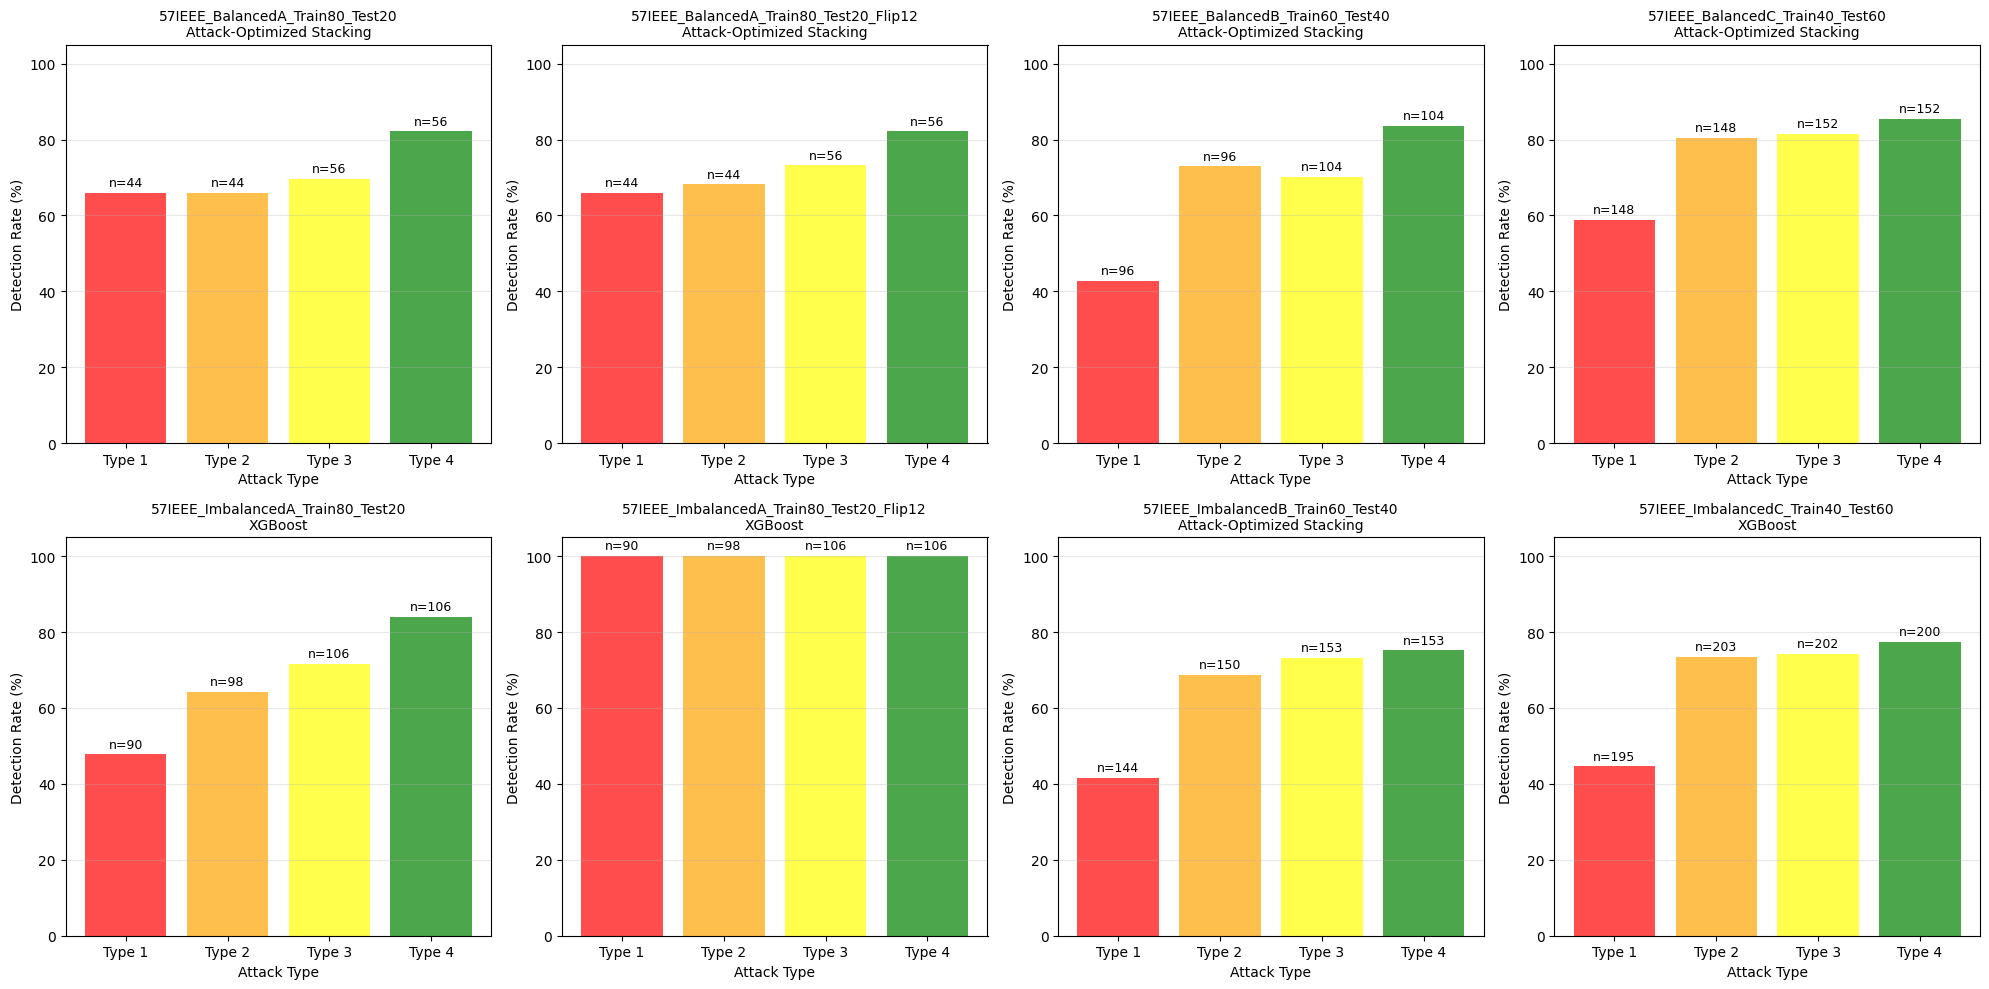


=== Operational Impact Score: 0.195 (LOW risk) ===

=== Operational Impact Score: 0.081 (LOW risk) ===

=== Operational Impact Score: 0.081 (LOW risk) ===

=== Operational Impact Score: 0.081 (LOW risk) ===

=== Operational Impact Score: 0.081 (LOW risk) ===

=== Operational Impact Score: 0.078 (LOW risk) ===

=== Operational Impact Score: 0.199 (LOW risk) ===

=== Operational Impact Score: 0.070 (LOW risk) ===

=== Operational Impact Score: 0.081 (LOW risk) ===

=== Operational Impact Score: 0.081 (LOW risk) ===

=== Operational Impact Score: 0.062 (LOW risk) ===

=== Operational Impact Score: 0.081 (LOW risk) ===

=== Operational Impact Score: 0.118 (LOW risk) ===

=== Operational Impact Score: 0.086 (LOW risk) ===

=== Operational Impact Score: 0.086 (LOW risk) ===

=== Operational Impact Score: 0.086 (LOW risk) ===

=== Operational Impact Score: 0.086 (LOW risk) ===

=== Operational Impact Score: 0.086 (LOW risk) ===

=== Operational Impact Score: 0.122 (LOW risk) ===

=== Operati

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import joblib
from sklearn.preprocessing import  StandardScaler, MinMaxScaler
from sklearn.model_selection import BaseCrossValidator,RandomizedSearchCV
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, roc_curve, auc, roc_auc_score
from sklearn.feature_selection import  mutual_info_classif

from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier, ExtraTreesClassifier)
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import make_scorer, fbeta_score
from sklearn.metrics import (
    accuracy_score, f1_score, recall_score, precision_score,
    roc_auc_score, precision_recall_curve, fbeta_score
    )
import os

# Create all necessary directories upfront
base_experiments_dir = 'experiments_N57'
os.makedirs(base_experiments_dir, exist_ok=True)

# Also create the subdirectories that will be needed
experiment_names = [
    "57IEEE_BalancedA_Train80_Test20",
    "57IEEE_BalancedA_Train80_Test20_Flip12",
    "57IEEE_BalancedB_Train60_Test40",
    "57IEEE_BalancedC_Train40_Test60",
    "57IEEE_ImbalancedA_Train80_Test20",
    "57IEEE_ImbalancedA_Train80_Test20_Flip12",
    "57IEEE_ImbalancedB_Train60_Test40",
    "57IEEE_ImbalancedC_Train40_Test60"
]

for exp_name in experiment_names:
    exp_dir = os.path.join(base_experiments_dir, exp_name)
    subdirs = [
        'models',
        os.path.join('figures', 'confusion_matrices'),
        os.path.join('figures', 'roc_curves'),
        os.path.join('figures', 'feature_importance'),
        os.path.join('figures', 'model_comparison'),
        os.path.join('figures', 'temporal_analysis')
    ]
    
    for subdir in subdirs:
        full_path = os.path.join(exp_dir, subdir)
        os.makedirs(full_path, exist_ok=True)
        print(f"Created: {full_path}")



# import shap for model interpretability
import shap

import warnings
warnings.filterwarnings('ignore')


# Set the number of cores for parallel processing
n_cores = max(1, os.cpu_count() // 2)
print(f"Using {n_cores} CPU cores for parallel processing")





class ImprovedSequentialCV(BaseCrossValidator):
    """
    
    Critical Rules:
    1. Training indices ALWAYS < Validation indices (temporal order)
    2. No overlap between training and validation sets
    3. Never touches test repetitions (prevents data leakage)
    4. Mixed temporal-stratified splits for small datasets
    5. Overlapping validation windows to increase robustness
    6. Conservative hyperparameter search space for small datasets
    7. Early stopping based on validation performance
    """
    
    def __init__(self, n_splits=3, min_samples_per_split=50, overlap_ratio=0.2, random_state=42):
        self.n_splits = n_splits
        self.min_samples_per_split = min_samples_per_split
        self.overlap_ratio = overlap_ratio
        self.random_state = random_state
        np.random.seed(random_state)
    
    def split(self, X, y, groups=None):
        """Create improved splits based on dataset size and temporal structure."""
        n_samples = len(X)
        
        # Determine the number of full 'repetition' units within this X (training data)
        # Each repetition is 384 days, but X could be a subset.
        # Our `ssn` is like '11', '12', ..., '54', where the first digit is the repetition.
        # So we need to calculate repetitions based on the *original* ssn. 
        
        # A more robust way to get 'estimated_reps' for CV would be to extract it from 'groups'
        # if `groups` represents repetitions, or calculate based on 'original_ssn' if available
        # within X for internal CV.
        # For simplicity, assuming `n_samples / 400` is a rough estimate for internal CV.
        estimated_reps = max(1, round(n_samples / 400)) # 400 is approx 4 seasons * 100 days
        
        print(f"Sequential CV: {n_samples} samples, ~{estimated_reps} training repetitions for internal CV")
        
        splits_yielded = 0
        if estimated_reps <= 1:
            for train_idx, val_idx in self._hybrid_small_dataset_splits(X, y):
                yield train_idx, val_idx
                splits_yielded += 1
                if splits_yielded >= self.n_splits: break
        elif estimated_reps == 2:
            for train_idx, val_idx in self._overlapping_temporal_splits(X, y):
                yield train_idx, val_idx
                splits_yielded += 1
                if splits_yielded >= self.n_splits: break
        elif estimated_reps == 3:
            for train_idx, val_idx in self._conservative_medium_splits(X, y):
                yield train_idx, val_idx
                splits_yielded += 1
                if splits_yielded >= self.n_splits: break
        else:
            # Large: Use general sequential approach
            # Aim for 3-5 splits
            for train_idx, val_idx in self._large_dataset_splits(X, y, estimated_reps):
                yield train_idx, val_idx
                splits_yielded += 1
                if splits_yielded >= self.n_splits: break
            
    def _hybrid_small_dataset_splits(self, X, y):
        """ Conservative temporal splits for very small datasets. (20-80 scenario)"""
        n_samples = len(X)
        print(" Using very conservative temporal splits for very small dataset")

        # Split 1: First 60% temporal, last 40% validation
        split_point_1 = int(n_samples * 0.6)
        train_idx_1 = np.arange(0, split_point_1)
        val_idx_1 = np.arange(split_point_1, n_samples)

        if len(val_idx_1) >= self.min_samples_per_split and len(train_idx_1) >= self.min_samples_per_split:
            yield train_idx_1, val_idx_1
            # print(f"  Split 1: Temporal 60-40 ({len(train_idx_1)}-{len(val_idx_1)} samples)")

        # Split 2: First 70% temporal, last 30% validation
        split_point_2 = int(n_samples * 0.7)
        train_idx_2 = np.arange(0, split_point_2)
        val_idx_2 = np.arange(split_point_2, n_samples)

        if len(val_idx_2) >= self.min_samples_per_split and len(train_idx_2) >= self.min_samples_per_split:
            # Ensure this split is distinct enough or provides new temporal view
            if not np.array_equal(train_idx_1, train_idx_2) or not np.array_equal(val_idx_1, val_idx_2):
                yield train_idx_2, val_idx_2
                # print(f"  Split 2: Temporal 70-30 ({len(train_idx_2)}-{len(val_idx_2)} samples)")
        
        # SPlt 3: First 80% temporal, last 20% validation
        split_point_3 = int(n_samples * 0.8)
        train_idx_3 = np.arange(0, split_point_3)
        val_idx_3 = np.arange(split_point_3, n_samples)
        
        if len(val_idx_3) >= self.min_samples_per_split and len(train_idx_3) >= self.min_samples_per_split:
            # Ensure this split is distinct enough or provides new temporal view
            if not np.array_equal(train_idx_1, train_idx_3) or not np.array_equal(val_idx_1, val_idx_3):
                yield train_idx_3, val_idx_3
                # print(f"  Split 3: Temporal 80-20 ({len(train_idx_3)}-{len(val_idx_3)} samples)")
        
    def _overlapping_temporal_splits(self, X, y):
        """Overlapping temporal splits for small datasets (40-60 scenario)."""
        n_samples = len(X)
        window_size = int(n_samples * 0.6) # 60% window
        overlap = int(window_size * self.overlap_ratio)
        
        print(" Using overlapping temporal windows")
        
        splits_created = 0
        # Start positions to create overlapping windows
        start_positions = [0]
        if n_samples > window_size + overlap:
            start_positions.append(overlap)
        if n_samples > window_size + 2 * overlap:
            start_positions.append(2 * overlap)
        
        for i, start in enumerate(start_positions):
            if splits_created >= self.n_splits:
                break
            
            # Train on current window
            train_end = min(start + window_size, n_samples - self.min_samples_per_split)
            val_start = train_end
            val_end = n_samples # Validate on remaining data
            
            if val_end - val_start >= self.min_samples_per_split and train_end - start >= self.min_samples_per_split:
                train_idx = np.arange(start, train_end)
                val_idx = np.arange(val_start, val_end)
                
                yield train_idx, val_idx
                splits_created += 1
                # print(f"  Split {splits_created}: Window {start}-{train_end} → {val_start}-{val_end}")
        
    def _conservative_medium_splits(self, X, y):
        """Conservative splits for medium datasets (60-40 scenario)."""
        n_samples = len(X)
        rep_size = n_samples // 3 # Assuming approx 3 repetitions
        
        print(" Using conservative temporal splits with validation")
        
        # Split 1: Rep 1 -> Rep 2 (conservative)
        train_idx = np.arange(0, rep_size)
        val_idx = np.arange(rep_size, 2 * rep_size)
        if len(val_idx) >= self.min_samples_per_split and len(train_idx) >= self.min_samples_per_split:
            yield train_idx, val_idx
            # print(f"  Split 1: Train Rep 1, Val Rep 2 ({len(train_idx)}-{len(val_idx)} samples)")
        
        # Split 2: Rep 1-2 -> Rep 3 (full available training)
        train_idx = np.arange(0, 2 * rep_size)
        val_idx = np.arange(2 * rep_size, 3 * rep_size)
        if len(val_idx) >= self.min_samples_per_split and len(train_idx) >= self.min_samples_per_split:
            yield train_idx, val_idx
            # print(f"  Split 2: Train Rep 1-2, Val Rep 3 ({len(train_idx)}-{len(val_idx)} samples)")
        
        # Split 3: Rep 2 -> Rep 3 (if enough data)
        train_idx = np.arange(rep_size, 2 * rep_size)
        val_idx = np.arange(2 * rep_size, 3 * rep_size)
        if len(val_idx) >= self.min_samples_per_split and len(train_idx) >= self.min_samples_per_split:
            yield train_idx, val_idx
            # print(f"  Split 3: Train Rep 2, Val Rep 3 ({len(train_idx)}-{len(val_idx)} samples)")    

    def _large_dataset_splits(self, X, y, n_reps):
        """Sequential splits for 4+ training repetitions (80-20 scenario)."""
        n_samples = len(X)
        samples_per_rep = n_samples // n_reps
        splits_created = 0
        
        # Split 1: Train on Rep 1-2, Validate on Rep 3
        if n_reps >= 3 and splits_created < self.n_splits:
            train_end = 2 * samples_per_rep
            val_start = train_end
            val_end = 3 * samples_per_rep
            
            if val_end - val_start >= self.min_samples_per_split and train_end - 0 >= self.min_samples_per_split:
                yield np.arange(0, train_end), np.arange(val_start, val_end)
                splits_created += 1
                # print(f"  Split {splits_created}: Train Rep 1-2, Val Rep 3")
        
        # Split 2: Train on Rep 1-3, Validate on Rep 4
        if n_reps >= 4 and splits_created < self.n_splits:
            train_end = 3 * samples_per_rep
            val_start = train_end
            val_end = 4 * samples_per_rep
            
            if val_end - val_start >= self.min_samples_per_split and train_end - 0 >= self.min_samples_per_split:
                yield np.arange(0, train_end), np.arange(val_start, val_end)
                splits_created += 1
                # print(f"  Split {splits_created}: Train Rep 1-3, Val Rep 4")
        
        # Split 3: Train on Rep 2-3, Validate on Rep 4 (if enough data and not too many splits already)
        if n_reps >= 4 and splits_created < self.n_splits:
            train_start = 1 * samples_per_rep
            train_end = 3 * samples_per_rep
            val_start = 3 * samples_per_rep
            val_end = 4 * samples_per_rep
            
            if val_end - val_start >= self.min_samples_per_split and train_end - train_start >= self.min_samples_per_split:
                yield np.arange(train_start, train_end), np.arange(val_start, val_end)
                splits_created += 1
                # print(f"  Split {splits_created}: Train Rep 2-3, Val Rep 4")

    def get_n_splits(self, X=None, y=None, groups=None):
        return self.n_splits


    
class CybersecurityMLPipeline:
    """Clean ML Pipeline with proper sequential cross-validation for 8+ models"""
    
    def __init__(self, train_ratio, experiment_name):
        self.train_ratio = train_ratio
        self.test_ratio = 1 - train_ratio
        self.experiment_name = experiment_name
        self.results = {}
        self.models = {}
        self.is_small_dataset = train_ratio <= 0.4 # Define small dataset for dynamic param tuning
        self.feature_store = {} # Initialize the feature store here
        self.setup_directories()
        self.feature_columns_after_selection = None # for shap 
    
        
        self.is_imbalanced = None
        self.attack_ratio = None
        self.distribution_shift = False
        
    def setup_directories(self):
        """Create organized directory structure."""
        base_dir = f'experiments_N57/{self.experiment_name}'
        
        subdirs = ['models', 'figures/confusion_matrices', 'figures/roc_curves',
                   'figures/feature_importance', 'figures/model_comparison', 'figures/temporal_analysis',]
        
        for subdir in subdirs:
            os.makedirs(f'{base_dir}/{subdir}', exist_ok=True)
        
        self.base_dir = base_dir
        print(f"Created directory structure for {self.experiment_name}")
        
    def create_repetition_based_split(self, df):
        """Create proper repetition-based train/test splits, strictly respecting temporal order."""
        print(f"\n=== Creating Repetition-Based Split ({self.train_ratio*100:.0f}-{self.test_ratio*100:.0f}) ===")
        
        # Extract repetition number from ssn. Assuming ssn format 'R_S' where R is repetition, S is season.
        # Your ssn is like '11', '12', ..., '54'. So, first digit is repetition.
        df['repetition'] = df['ssn'].astype(str).str[0].astype(int)
        
        unique_reps = sorted(df['repetition'].unique())
        print(f"Available repetitions: {unique_reps}")
        
        # Calculate repetitions for training vs testing
        total_reps = len(unique_reps)
        n_train_reps = max(1, int(total_reps * self.train_ratio))
        
        train_reps = unique_reps[:n_train_reps]
        test_reps = unique_reps[n_train_reps:]
        
        print(f"Training repetitions: {train_reps}")
        print(f"Test repetitions: {test_reps}")
        
        # Create splits
        train_data = df[df['repetition'].isin(train_reps)].copy()
        test_data = df[df['repetition'].isin(test_reps)].copy()
        
        print(f"\nData distribution:")
        print(f"Train: {len(train_data)} samples ({len(train_data)/len(df):.1%})")
        print(f"Test: {len(test_data)} samples ({len(test_data)/len(df):.1%})")
        
        print(f"Attack distribution:")
        print(f"Train: {train_data['attack'].mean():.2%}")
        print(f"Test: {test_data['attack'].mean():.2%}")
   
        max_train_time = train_data['temporal_index'].max()
        min_test_time = test_data['temporal_index'].min()
        if min_test_time <= max_train_time:
            raise ValueError(f"Temporal leakage: Test data starts at {min_test_time} "
                            f"while train ends at {max_train_time}")
        
        return train_data, test_data

    
            
    def enhanced_feature_selection(self, X_train, X_test, y_train):
        """
        Aggressive feature selection for overfitting prevention
        """
        n_samples = len(X_train)
        print(f"\n=== Enhanced Feature Selection with Overfitting Prevention ===")
        
        # 1. First, identify truly numeric columns (exclude object types)
        numeric_cols = []
        non_numeric_cols = []
        
        for col in X_train.columns:
            # Check if column contains numeric data
            if X_train[col].dtype in ['int64', 'float64', 'int32', 'float32']:
                numeric_cols.append(col)
            else:
                # Check if it can be converted to numeric
                try:
                    pd.to_numeric(X_train[col], errors='coerce')
                    # If more than 50% are successfully converted, treat as numeric
                    if pd.to_numeric(X_train[col], errors='coerce').notna().sum() > len(X_train) * 0.5:
                        numeric_cols.append(col)
                    else:
                        non_numeric_cols.append(col)
                except:
                    non_numeric_cols.append(col)
        
        print(f"Found {len(numeric_cols)} truly numeric features")
        print(f"Found {len(non_numeric_cols)} non-numeric features: {non_numeric_cols[:10]}")
        
        # 2. Remove problematic non-numeric columns
        # These are columns that cannot be used by ML models directly
        exclude_patterns = ['peak_hour_bus', 'ft']  # Add patterns of problematic columns
        
        numeric_cols_filtered = []
        for col in numeric_cols:
            exclude = False
            for pattern in exclude_patterns:
                if pattern in col:
                    exclude = True
                    break
            if not exclude:
                numeric_cols_filtered.append(col)
        
        print(f"After filtering problematic columns: {len(numeric_cols_filtered)} features")
        
        # 3. Calculate MI scores only for valid numeric features
        if numeric_cols_filtered:
            # Ensure all values are numeric
            X_train_numeric = X_train[numeric_cols_filtered].apply(pd.to_numeric, errors='coerce').fillna(0)
            mi_scores = mutual_info_classif(X_train_numeric, y_train, random_state=42)
        else:
            mi_scores = []
        
        # 4. Create feature scores dataframe
        feature_scores = pd.DataFrame({
            'feature': numeric_cols_filtered,
            'mi_score': mi_scores
        }).sort_values('mi_score', ascending=False)
        

        if n_samples > 1200:
            n_features = min(200, len(numeric_cols_filtered)) 
        elif n_samples > 900:
            n_features = min(100, len(numeric_cols_filtered)) 
        else:
            n_features = min(50, len(numeric_cols_filtered))  
    
        # 6. Select top features
        if len(feature_scores) > 0:
            # Only keep features with MI > 0.001
            meaningful_features = feature_scores[feature_scores['mi_score'] > 0.0001]
            n_features = min(n_features, len(meaningful_features))
            selected_features = meaningful_features.head(n_features)['feature'].tolist()
        else:
            selected_features = []
        
        print(f"Selected top {len(selected_features)} features")
        
        if len(feature_scores) > 0:
            print("\nTop 10 features by MI score:")
            for i, row in feature_scores.head(10).iterrows():
                print(f"  {row['feature']}: MI={row['mi_score']:.4f}")
        
        # 7. Ensure all selected features are numeric in both train and test
        X_train_selected = X_train[selected_features].apply(pd.to_numeric, errors='coerce').fillna(0)
        X_test_selected = X_test[selected_features].apply(pd.to_numeric, errors='coerce').fillna(0)
        
        # 8. Identify features for scaling
        scale_patterns_for_lr = [
            # Distance and score metrics
            'distance', 'score', 'zscore', 'deviation',
            # Generator statistics that need scaling
            '_mean', '_std', '_max', '_min', '_range',
            '_capacity_factor', '_utilization',
            # Ramp features (continuous values)
            'ramp_up', 'ramp_down', 'ramp_std',
            # Flow and angle deviations
            'flow_deviation', 'angle_deviation',
            # Temporal features
            'fval', 'roll_mean', 'lag', 'diff',
            # Fleet features
            'total_generation', 'gen_concentration', 'gen_diversity',
            # KNN distances
            'knn_distance'
        ]

        no_scale_patterns = [
            # Counts and violations (discrete)
            'violations', 'starts', 'stops', 'cycles', 'hours_',
            'consecutive_', 'active_generators',
            # Binary/categorical
            'is_', 'has_', 'binary', 'detected', 'type',
            # Rankings and indices
            'rank', 'order', 'position', 'temporal_index',
            # IDs
            'ssn', 'repetition', 'year', 'day', 'hour',
            # Correlation values (already -1 to 1)
            'correlation', 'inversions'
        ]    
        
        features_to_scale_lr = []
        features_no_scale = []
        
        for col in selected_features:
            col_lower = col.lower()
            if any(pattern in col_lower for pattern in no_scale_patterns):
                features_no_scale.append(col)
            elif any(pattern in col_lower for pattern in scale_patterns_for_lr):
                features_to_scale_lr.append(col)
            else:
                features_to_scale_lr.append(col)
        
        print(f"\nFeatures for LR scaling: {len(features_to_scale_lr)}")
        print(f"Features never scaled: {len(features_no_scale)}")
        
        self.preprocessing = {
            'selected_feature_names': selected_features,
            'features_to_scale_lr': features_to_scale_lr,
            'features_no_scale': features_no_scale
        }
        
        self.feature_columns_after_selection = selected_features
        
        return X_train_selected, X_test_selected

       
    
  
    def evaluate_model(self, model, X_train, X_test, y_train, y_test, model_name):
        """Enhanced model evaluation with custom metrics"""
        
        # Train and predict
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        
        # Calculate all metrics
        test_acc = accuracy_score(y_test, y_pred)
        test_f1 = f1_score(y_test, y_pred)
        test_tpr = recall_score(y_test, y_pred)
        print(f"Test TPR (Recall): {test_tpr:.4f}")
        
        # Calculate ROC AUC if possible
        roc_auc = None
        if hasattr(model, "predict_proba") and len(np.unique(y_test)) > 1:
            try:
                y_proba = model.predict_proba(X_test)[:, 1]
                roc_auc = roc_auc_score(y_test, y_proba)
            except Exception as e:
                print(f"  Warning: Could not calculate ROC AUC ({e})")
        
        # Train metrics for overfitting detection
        train_pred = model.predict(X_train)
        train_acc = accuracy_score(y_train, train_pred)
        train_f1 = f1_score(y_train, train_pred)
      
        
        # Overfitting gaps
        acc_gap = train_acc - test_acc
        f1_gap = train_f1 - test_f1
  
        
        print(f"\n{model_name} Results:")
        print(f"Test Accuracy: {test_acc:.4f}")
        print(f"Test F1: {test_f1:.4f}")
     
        if roc_auc is not None:
            print(f"ROC AUC: {roc_auc:.4f}")
        
        print(f"\nTrain Metrics:")
        print(f"Train Accuracy: {train_acc:.4f}")
        print(f"Train F1: {train_f1:.4f}")
       
        
        print(f"\nOverfitting Analysis:")
        print(f"Accuracy Gap: {acc_gap:.4f}")
        print(f"F1 Gap: {f1_gap:.4f}")
        
        
        # Overfitting detection with custom threshold
        n_samples = len(X_train)
        overfitting_threshold = 0.3 if n_samples < 500 else 0.2
        if acc_gap > overfitting_threshold or f1_gap > overfitting_threshold:
            print(f"  ⚠️  WARNING: Potential overfitting detected!")
            overfitting_detected = True
        else:
            overfitting_detected = False
        
        # Check for suspicious results (too good to be true, might indicate leakage)
        if test_acc > 0.98 and test_f1 > 0.98:
            print("⚠️  WARNING: Unusually high performance detected - double-check for data leakage!")
                
        safe_name = model_name.replace(" ", "_")  # Move this before SHAP

        if not overfitting_detected and test_acc > 0.95:
            print("Running SHAP analysis for model interpretation...")
            try:
                feature_names = self.feature_columns_after_selection
                
                explainer = shap.TreeExplainer(model)
                
                # Handle both binary and multi-class outputs
                shap_values = explainer.shap_values(X_test)
                if isinstance(shap_values, list) and len(shap_values) == 2:
                    # Binary classification - use positive class
                    shap_values = shap_values[1]
                
                # Create DataFrame with feature names for better visualization
                if feature_names is not None:
                    X_test_df = pd.DataFrame(X_test, columns=feature_names)
                    shap.summary_plot(shap_values, X_test_df, show=False)
                else:
                    shap.summary_plot(shap_values, X_test, show=False)
                    
                plt.tight_layout()
                
                # Ensure feature importance directory exists
                fi_dir = f'{self.base_dir}/figures/feature_importance'
                os.makedirs(fi_dir, exist_ok=True)
                
                plt.savefig(f'{fi_dir}/{safe_name}_shap.png', 
                            dpi=300, bbox_inches='tight')
                plt.close()
            except Exception as e:
                print(f"  SHAP analysis failed: {str(e)}")
                    
        # Confusion Matrix
        cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
        tn, fp, fn, tp = cm.ravel()
        print(f"Confusion Matrix:\n{cm}")
        print(f"TN: {tn}, FP: {fp}")
        print(f"FN: {fn}, TP: {tp}")
        
        plt.figure(figsize=(8, 6))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                    xticklabels=['Normal', 'Attack'],
                    yticklabels=['Normal', 'Attack'])
        plt.title(f'Confusion Matrix - {model_name}\n({self.experiment_name})')
        plt.xlabel('Predicted')
        plt.ylabel('Actual')
        
        safe_name = model_name.replace(" ", "_")
        
        # Ensure the directory exists before saving
        cm_dir = f'{self.base_dir}/figures/confusion_matrices'
        os.makedirs(cm_dir, exist_ok=True)
        
        plt.savefig(f'{cm_dir}/{safe_name}_confusion_matrix.png',
                    dpi=300, bbox_inches='tight')
        plt.close()
        
        # ROC curve - also ensure directory exists
        if roc_auc is not None:
            y_proba = model.predict_proba(X_test)[:, 1]
            fpr, tpr, _ = roc_curve(y_test, y_proba)
            
            plt.figure()
            plt.plot(fpr, tpr, color='darkorange', lw=2,
                    label=f'ROC curve (AUC = {roc_auc:.2f})')
            plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
            plt.xlabel('False Positive Rate')
            plt.ylabel('True Positive Rate')
            plt.title(f'ROC Curve - {model_name}')
            plt.legend(loc="lower right")
            plt.grid(True, alpha=0.3)
            
            # Ensure ROC directory exists
            roc_dir = f'{self.base_dir}/figures/roc_curves'
            os.makedirs(roc_dir, exist_ok=True)
            
            plt.savefig(f'{roc_dir}/{safe_name}_roc_curve.png',
                        dpi=300, bbox_inches='tight')
            plt.close()
        return {
            'model': model,
            'test_accuracy': test_acc,
            'test_f1': test_f1,
            'test_tpr': test_tpr,  # Added TPR
            'roc_auc': roc_auc,
            'overfitting_score': max(acc_gap, f1_gap),
            'overfitting_detected': overfitting_detected
        }


    def analyze_attack_type_predictions(self, model, X_test, y_test, test_data, model_name):
        """Analyze predictions for each attack type (1, 2, 3, 4)"""
        
        # Get predictions
        y_pred = model.predict(X_test)
        
        # Create a dataframe with actual and predicted values
        results_df = pd.DataFrame({
            'actual_attack': y_test.values,
            'predicted_attack': y_pred,
            'actual_type': test_data['type_of_attack'].values,
            'predicted_type': 0  # Initialize as normal
        })
        
     
        
        # Create attack type confusion matrix
        print(f"\n=== Attack Type Analysis for {model_name} ===")
        
        # Count predictions by actual attack type
        attack_type_results = {}
        for attack_type in [0, 1, 2, 3, 4]:  # 0 = normal, 1-4 = attack types
            type_mask = results_df['actual_type'] == attack_type
            type_data = results_df[type_mask]
            
            n_total = len(type_data)
            n_predicted_attack = (type_data['predicted_attack'] == 1).sum()
            n_predicted_normal = (type_data['predicted_attack'] == 0).sum()
            
            attack_type_results[attack_type] = {
                'total': n_total,
                'predicted_as_attack': n_predicted_attack,
                'predicted_as_normal': n_predicted_normal,
                'detection_rate': n_predicted_attack / n_total if n_total > 0 else 0
            }
        
        # Print detailed breakdown
        print("\nDetection Rate by Attack Type:")
        print("-" * 60)
        print(f"{'Attack Type':<15} {'Total':<10} {'Detected':<10} {'Missed':<10} {'Detection %':<12}")
        print("-" * 60)
        
        for atype in [1, 2, 3, 4]:  # Only attack types
            if atype in attack_type_results:
                r = attack_type_results[atype]
                if r['total'] > 0:
                    print(f"Type {atype:<10} {r['total']:<10} {r['predicted_as_attack']:<10} "
                        f"{r['predicted_as_normal']:<10} {r['detection_rate']*100:<10.1f}%")
        
        # Normal class performance
        if 0 in attack_type_results:
            r = attack_type_results[0]
            if r['total'] > 0:
                print(f"{'Normal':<15} {r['total']:<10} {r['predicted_as_normal']:<10} "
                    f"{r['predicted_as_attack']:<10} {(1-r['detection_rate'])*100:<10.1f}%")
        
        print("-" * 60)
        
        # Overall attack detection (combining all attack types)
        total_attacks = sum(attack_type_results[t]['total'] for t in [1,2,3,4] if t in attack_type_results)
        detected_attacks = sum(attack_type_results[t]['predicted_as_attack'] for t in [1,2,3,4] if t in attack_type_results)
        
        print(f"\nOverall Attack Detection: {detected_attacks}/{total_attacks} = "
            f"{detected_attacks/total_attacks*100:.1f}%" if total_attacks > 0 else "N/A")
        
        return attack_type_results
    
    def calculate_normal_baselines(self, train_data_full, X_train_ft):
        """
        Calculate normal baselines once and store them for reuse across all models
        """
        print("\n--- Calculating Normal Baselines from Training Data (ONCE) ---")
        
        N_BUSES = 57  
        N_HOURS = 24
        FEATURES_PER_HOUR = 270
        
        normal_baselines = {}
        
        for ssn in train_data_full['original_ssn'].unique():
            ssn = int(ssn)
            ssn_mask = (train_data_full['original_ssn'] == ssn) & (train_data_full['attack'] == 0)
            ssn_normal_indices = np.where(ssn_mask)[0]
            
            if len(ssn_normal_indices) == 0:
                continue
                
            normal_baselines[ssn] = {}
            
            for hour in range(N_HOURS):
                hour_stats = {
                    'active_generators': [], 
                    'total_dispatch': [],
                    'per_gen_dispatch': {bus: [] for bus in range(N_BUSES)}
                }
                
                for idx in ssn_normal_indices:
                    active_count = 0
                    total_gen = 0
                    
                    for bus in range(N_BUSES):
                        col_name = f'ft{hour * FEATURES_PER_HOUR + bus + 1}'
                        if col_name in X_train_ft.columns:
                            value = X_train_ft.iloc[idx][col_name]
                            hour_stats['per_gen_dispatch'][bus].append(value)
                            
                            if value > 0.01:
                                active_count += 1
                                total_gen += value
                    
                    hour_stats['active_generators'].append(active_count)
                    hour_stats['total_dispatch'].append(total_gen)
                
                if hour_stats['active_generators']:
                    # Calculate aggregate statistics
                    mean_active = np.mean(hour_stats['active_generators'])
                    std_active = np.std(hour_stats['active_generators'])
                    std_active = max(std_active, 0.5)
                    
                    mean_dispatch = np.mean(hour_stats['total_dispatch'])
                    std_dispatch = np.std(hour_stats['total_dispatch'])
                    std_dispatch = max(std_dispatch, mean_dispatch * 0.1, 0.1)
                    
                    # Calculate per-generator statistics
                    per_gen_stats = {}
                    for bus in range(N_BUSES):
                        if hour_stats['per_gen_dispatch'][bus]:
                            dispatch_values = hour_stats['per_gen_dispatch'][bus]
                            per_gen_stats[bus] = {
                                'mean': np.mean(dispatch_values),
                                'std': max(np.std(dispatch_values), 0.01),
                                'percentile_95': np.percentile(dispatch_values, 95),
                                'percentile_5': np.percentile(dispatch_values, 5),
                                'max': np.max(dispatch_values),
                                'is_normally_active': np.mean(np.array(dispatch_values) > 0.01) > 0.5
                            }
                    
                    normal_baselines[ssn][hour] = {
                        'mean_active_gens': mean_active,
                        'std_active_gens': std_active,
                        'mean_total_dispatch': mean_dispatch,
                        'std_total_dispatch': std_dispatch,
                        'per_gen_stats': per_gen_stats
                    }
        
        print(f"Calculated baselines for {len(normal_baselines)} SSNs")
        
        # Sample baseline print
        if normal_baselines:
            sample_ssn = list(normal_baselines.keys())[0]
            sample_hour = 0
            if sample_hour in normal_baselines[sample_ssn]:
                print(f"Sample baseline (SSN {sample_ssn}, Hour {sample_hour}):")
                print(f"  Active gens: {normal_baselines[sample_ssn][sample_hour]['mean_active_gens']:.2f} ± {normal_baselines[sample_ssn][sample_hour]['std_active_gens']:.2f}")
                print(f"  Total dispatch: {normal_baselines[sample_ssn][sample_hour]['mean_total_dispatch']:.2f} ± {normal_baselines[sample_ssn][sample_hour]['std_total_dispatch']:.2f}")
                print(f"  Per-gen stats tracked for {len(normal_baselines[sample_ssn][sample_hour]['per_gen_stats'])} generators")
        
        return normal_baselines
    
    def analyze_comprehensive_dispatch_impact_v2(self, model, X_train, X_test, y_train, y_test, 
                                            X_train_ft, X_test_ft, train_data_full, test_data_full, 
                                            model_name, normal_baselines):
        """
        Comprehensive dispatch analysis using precomputed normal baselines.
        """
        # Get predictions
        y_pred = model.predict(X_test)
        print(f"\n=== Comprehensive Dispatch Impact Analysis for {model_name} ===")
        
        N_BUSES = 57  
        N_HOURS = 24
        FEATURES_PER_HOUR = 270
        
        print(f"Using {X_train_ft.shape[1]} ft columns for dispatch analysis")
        print(f"Using precomputed normal baselines for {len(normal_baselines)} SSNs")
        
        # Quick generation pattern check (hour 0)
        print("\n--- Analyzing Generation Pattern ---")
        sample_hour_0_gens = []
        for bus in range(N_BUSES):
            col_name = f'ft{bus + 1}'
            if col_name in X_train_ft.columns:
                non_zero = (X_train_ft[col_name] > 0).sum()
                if non_zero > 0:
                    mean_gen = X_train_ft[col_name][X_train_ft[col_name] > 0].mean()
                    print(f"  Bus {bus+1}: {non_zero} samples with generation, mean={mean_gen:.3f}")
                    sample_hour_0_gens.append((bus+1, mean_gen))
        
        # Step 1: Use the precomputed normal baselines
        print("\n--- Using Precomputed Normal Baselines ---")
        
        # Step 2: Analyze attacks using both aggregate and per-generator metrics
        true_positives = np.where((y_test == 1) & (y_pred == 1))[0]
        false_negatives = np.where((y_test == 1) & (y_pred == 0))[0]
        
        print(f"\nTrue Positives: {len(true_positives)}")
        print(f"False Negatives: {len(false_negatives)}")
        
        results_by_type = {}
        
        for attack_type in [1, 2, 3, 4]:
            type_mask = test_data_full['type_of_attack'] == attack_type
            type_tp = [idx for idx in true_positives if type_mask.iloc[idx]]
            type_fn = [idx for idx in false_negatives if type_mask.iloc[idx]]
            
            if len(type_tp) == 0 and len(type_fn) == 0:
                continue
                
            print(f"\n--- Type {attack_type}: {len(type_tp)} detected, {len(type_fn)} missed ---")
            
            # Analyze True Positives
            tp_deviations = {
                'active_gen_dev': [], 
                'total_dispatch_dev': [],
                'max_gen_dev': [],
                'mean_gen_dev': [],
                'redistribution_score': []
            }
            
            for idx in type_tp:
                ssn = int(test_data_full.iloc[idx]['original_ssn'])
                if ssn not in normal_baselines:
                    continue
                    
                for hour in range(N_HOURS):
                    if hour not in normal_baselines[ssn]:
                        continue
                        
                    baseline = normal_baselines[ssn][hour]
                    
                    # Calculate aggregate metrics
                    active_count = 0
                    total_dispatch = 0
                    gen_deviations = []
                    significant_changes = 0
                    redistribution_changes = []
                    
                    for bus in range(N_BUSES):
                        col_name = f'ft{hour * FEATURES_PER_HOUR + bus + 1}'
                        if col_name in X_test_ft.columns:
                            attack_value = X_test_ft.iloc[idx][col_name]
                            
                            if attack_value > 0.01:
                                active_count += 1
                                total_dispatch += attack_value
                            
                            # Calculate per-generator deviation
                            if bus in baseline['per_gen_stats']:
                                gen_stats = baseline['per_gen_stats'][bus]
                                gen_dev = abs(attack_value - gen_stats['mean']) / gen_stats['std']
                                gen_deviations.append(gen_dev)
                                
                                # Check for significant changes
                                if gen_dev > 2.0:
                                    significant_changes += 1
                                
                                # Check for redistribution (active->inactive or vice versa)
                                was_active = gen_stats['is_normally_active']
                                is_active = attack_value > 0.01
                                if was_active != is_active:
                                    redistribution_changes.append(1)
                    
                    # Calculate aggregate deviations
                    active_dev = abs(active_count - baseline['mean_active_gens']) / baseline['std_active_gens']
                    dispatch_dev = abs(total_dispatch - baseline['mean_total_dispatch']) / baseline['std_total_dispatch']
                    
                    # Calculate per-generator metrics
                    if gen_deviations:
                        max_gen_dev = max(gen_deviations)
                        mean_gen_dev = np.mean(gen_deviations)
                    else:
                        max_gen_dev = 0
                        mean_gen_dev = 0
                    
                    redistribution_score = significant_changes / max(len(baseline['per_gen_stats']), 1)
                    
                    # Store all metrics
                    tp_deviations['active_gen_dev'].append(active_dev)
                    tp_deviations['total_dispatch_dev'].append(dispatch_dev)
                    tp_deviations['max_gen_dev'].append(max_gen_dev)
                    tp_deviations['mean_gen_dev'].append(mean_gen_dev)
                    tp_deviations['redistribution_score'].append(redistribution_score)
            
            # Analyze False Negatives
            fn_deviations = {
                'active_gen_dev': [], 
                'total_dispatch_dev': [],
                'max_gen_dev': [],
                'mean_gen_dev': [],
                'redistribution_score': []
            }
            
            for idx in type_fn:
                ssn = int(test_data_full.iloc[idx]['original_ssn'])
                if ssn not in normal_baselines:
                    continue
                    
                for hour in range(N_HOURS):
                    if hour not in normal_baselines[ssn]:
                        continue
                        
                    baseline = normal_baselines[ssn][hour]
                    
                    # Calculate aggregate metrics
                    active_count = 0
                    total_dispatch = 0
                    gen_deviations = []
                    significant_changes = 0
                    
                    for bus in range(N_BUSES):
                        col_name = f'ft{hour * FEATURES_PER_HOUR + bus + 1}'
                        if col_name in X_test_ft.columns:
                            attack_value = X_test_ft.iloc[idx][col_name]
                            
                            if attack_value > 0.01:
                                active_count += 1
                                total_dispatch += attack_value
                            
                            # Calculate per-generator deviation
                            if bus in baseline['per_gen_stats']:
                                gen_stats = baseline['per_gen_stats'][bus]
                                gen_dev = abs(attack_value - gen_stats['mean']) / gen_stats['std']
                                gen_deviations.append(gen_dev)
                                
                                if gen_dev > 2.0:
                                    significant_changes += 1
                    
                    # Calculate deviations
                    active_dev = abs(active_count - baseline['mean_active_gens']) / baseline['std_active_gens']
                    dispatch_dev = abs(total_dispatch - baseline['mean_total_dispatch']) / baseline['std_total_dispatch']
                    
                    if gen_deviations:
                        max_gen_dev = max(gen_deviations)
                        mean_gen_dev = np.mean(gen_deviations)
                    else:
                        max_gen_dev = 0
                        mean_gen_dev = 0
                    
                    redistribution_score = significant_changes / max(len(baseline['per_gen_stats']), 1)
                    
                    fn_deviations['active_gen_dev'].append(active_dev)
                    fn_deviations['total_dispatch_dev'].append(dispatch_dev)
                    fn_deviations['max_gen_dev'].append(max_gen_dev)
                    fn_deviations['mean_gen_dev'].append(mean_gen_dev)
                    fn_deviations['redistribution_score'].append(redistribution_score)
            
            # Compute medians and ratios
            if tp_deviations['active_gen_dev'] and fn_deviations['active_gen_dev']:
                # Aggregate metrics
                tp_active_median = np.median(tp_deviations['active_gen_dev'])
                tp_dispatch_median = np.median(tp_deviations['total_dispatch_dev'])
                fn_active_median = np.median(fn_deviations['active_gen_dev'])
                fn_dispatch_median = np.median(fn_deviations['total_dispatch_dev'])
                
                # Per-generator metrics
                tp_max_gen_median = np.median(tp_deviations['max_gen_dev'])
                tp_mean_gen_median = np.median(tp_deviations['mean_gen_dev'])
                fn_max_gen_median = np.median(fn_deviations['max_gen_dev'])
                fn_mean_gen_median = np.median(fn_deviations['mean_gen_dev'])
                
                # Redistribution metrics
                tp_redist_median = np.median(tp_deviations['redistribution_score'])
                fn_redist_median = np.median(fn_deviations['redistribution_score'])
                
                # Calculate impact ratios (FN/TP - higher means FN is less detectable)
                active_ratio = min(fn_active_median / (tp_active_median + 0.1), 2.0)
                dispatch_ratio = min(fn_dispatch_median / (tp_dispatch_median + 0.1), 2.0)
                max_gen_ratio = min(fn_max_gen_median / (tp_max_gen_median + 0.1), 2.0)
                mean_gen_ratio = min(fn_mean_gen_median / (tp_mean_gen_median + 0.1), 2.0)
                redist_ratio = min(fn_redist_median / (tp_redist_median + 0.01), 2.0)
                
                print(f"  Detected - Active: {tp_active_median:.2f}σ, Total: {tp_dispatch_median:.2f}σ, MaxGen: {tp_max_gen_median:.2f}σ, MeanGen: {tp_mean_gen_median:.2f}σ, Redist: {tp_redist_median:.3f}")
                print(f"  Missed   - Active: {fn_active_median:.2f}σ, Total: {fn_dispatch_median:.2f}σ, MaxGen: {fn_max_gen_median:.2f}σ, MeanGen: {fn_mean_gen_median:.2f}σ, Redist: {fn_redist_median:.3f}")
                print(f"  Impact Ratios - Active: {active_ratio:.2f}, Total: {dispatch_ratio:.2f}, MaxGen: {max_gen_ratio:.2f}, MeanGen: {mean_gen_ratio:.2f}, Redist: {redist_ratio:.2f}")
                
                results_by_type[attack_type] = {
                    'detected': {
                        'active_gen_dev': tp_active_median,
                        'total_dispatch_dev': tp_dispatch_median,
                        'max_gen_dev': tp_max_gen_median,
                        'mean_gen_dev': tp_mean_gen_median,
                        'redistribution_score': tp_redist_median,
                        'count': len(type_tp)
                    },
                    'missed': {
                        'active_gen_dev': fn_active_median,
                        'total_dispatch_dev': fn_dispatch_median,
                        'max_gen_dev': fn_max_gen_median,
                        'mean_gen_dev': fn_mean_gen_median,
                        'redistribution_score': fn_redist_median,
                        'count': len(type_fn)
                    },
                    'impact_ratios': {
                        'active_generators': active_ratio,
                        'total_dispatch': dispatch_ratio,
                        'max_gen_deviation': max_gen_ratio,
                        'mean_gen_deviation': mean_gen_ratio,
                        'redistribution': redist_ratio
                    }
                }
            else:
                print(f"  Limited deviation data available")
                results_by_type[attack_type] = {
                    'detected': {
                        'active_gen_dev': 1.0, 
                        'total_dispatch_dev': 1.0, 
                        'max_gen_dev': 1.0,
                        'mean_gen_dev': 1.0,
                        'redistribution_score': 0.1,
                        'count': len(type_tp)
                    },
                    'missed': {
                        'active_gen_dev': 1.0, 
                        'total_dispatch_dev': 1.0,
                        'max_gen_dev': 1.0,
                        'mean_gen_dev': 1.0,
                        'redistribution_score': 0.1,
                        'count': len(type_fn)
                    },
                    'impact_ratios': {
                        'active_generators': 0.5, 
                        'total_dispatch': 0.5,
                        'max_gen_deviation': 0.5,
                        'mean_gen_deviation': 0.5,
                        'redistribution': 0.5
                    }
                }
        
        return results_by_type


    def create_dispatch_impact_visualization(self, model_results):
        """
        Create visualization showing comprehensive dispatch deviations for publication
        """
        
        # Collect all impact data from the new analysis structure
        all_impacts = []
        
        for model_name, result in model_results.items():
            if 'dispatch_impact' not in result:
                continue
                
            for attack_type, impact_data in result['dispatch_impact'].items():
                if 'impact_ratios' in impact_data:
                    all_impacts.append({
                        'Model': model_name,
                        'Attack_Type': attack_type,
                        'Active_Gen_Ratio': impact_data['impact_ratios']['active_generators'],
                        'Total_Dispatch_Ratio': impact_data['impact_ratios']['total_dispatch'],
                        'Detected_Active_Dev': impact_data['detected']['active_gen_dev'],
                        'Missed_Active_Dev': impact_data['missed']['active_gen_dev'],
                        'Detected_Dispatch_Dev': impact_data['detected']['total_dispatch_dev'],
                        'Missed_Dispatch_Dev': impact_data['missed']['total_dispatch_dev'],
                        'Detected_Count': impact_data['detected']['count'],
                        'Missed_Count': impact_data['missed']['count']
                    })
        
        if not all_impacts:
            print("No dispatch impact data to visualize")
            return
        
        impact_df = pd.DataFrame(all_impacts)
        
        # Create figure
        fig, axes = plt.subplots(2, 2, figsize=(14, 10))
        
        # Attack type descriptions
        attack_labels = {
            1: 'Ramp Rate',
            2: 'Upper Limit',
            3: 'Lower Limit',
            4: 'Economic'
        }
        
        # Plot 1: Active Generators - Detected vs Missed Deviations
        ax = axes[0, 0]
        x = np.arange(4)
        width = 0.35
        
        for attack_type in [1, 2, 3, 4]:
            type_data = impact_df[impact_df['Attack_Type'] == attack_type]
            if not type_data.empty:
                detected_dev = type_data['Detected_Active_Dev'].mean()
                missed_dev = type_data['Missed_Active_Dev'].mean()
                
                ax.bar(attack_type - 1 - width/2, detected_dev, width, 
                    label='Detected' if attack_type == 1 else '', color='red', alpha=0.7)
                ax.bar(attack_type - 1 + width/2, missed_dev, width,
                    label='Missed' if attack_type == 1 else '', color='blue', alpha=0.7)
        
        ax.set_xlabel('Attack Type', fontsize=12)
        ax.set_ylabel('Active Generators Deviation (σ)', fontsize=12)
        ax.set_title('(a) Active Generator Impact by Detection Status', fontsize=13)
        ax.set_xticks(x)
        ax.set_xticklabels([attack_labels[i+1] for i in range(4)])
        ax.legend(fontsize=11)
        ax.grid(True, alpha=0.3, axis='y')
        
        # Plot 2: Total Dispatch - Detected vs Missed Deviations
        ax = axes[0, 1]
        
        for attack_type in [1, 2, 3, 4]:
            type_data = impact_df[impact_df['Attack_Type'] == attack_type]
            if not type_data.empty:
                detected_dev = type_data['Detected_Dispatch_Dev'].mean()
                missed_dev = type_data['Missed_Dispatch_Dev'].mean()
                
                ax.bar(attack_type - 1 - width/2, detected_dev, width, 
                    label='Detected' if attack_type == 1 else '', color='red', alpha=0.7)
                ax.bar(attack_type - 1 + width/2, missed_dev, width,
                    label='Missed' if attack_type == 1 else '', color='blue', alpha=0.7)
        
        ax.set_xlabel('Attack Type', fontsize=12)
        ax.set_ylabel('Total Dispatch Deviation (σ)', fontsize=12)
        ax.set_title('(b) Total Dispatch Impact by Detection Status', fontsize=13)
        ax.set_xticks(x)
        ax.set_xticklabels([attack_labels[i+1] for i in range(4)])
        ax.legend(fontsize=11)
        ax.grid(True, alpha=0.3, axis='y')
        
        # Plot 3: Combined Impact Ratios
        ax = axes[1, 0]
        
        # Calculate average ratios by attack type
        avg_ratios = impact_df.groupby('Attack_Type')[['Active_Gen_Ratio', 'Total_Dispatch_Ratio']].mean()
        
        x = np.arange(len(avg_ratios))
        width = 0.35
        
        bars1 = ax.bar(x - width/2, avg_ratios['Active_Gen_Ratio'].values, width, 
                    label='Active Generators', color='green', alpha=0.7)
        bars2 = ax.bar(x + width/2, avg_ratios['Total_Dispatch_Ratio'].values, width,
                    label='Total Dispatch', color='orange', alpha=0.7)
        
        ax.set_xlabel('Attack Type', fontsize=12)
        ax.set_ylabel('Impact Ratio (Missed/Detected)', fontsize=12)
        ax.set_title('(c) Relative Impact of Undetected Attacks', fontsize=13)
        ax.set_xticks(x)
        
        attack_labels = {1: 'Ramp Rate', 2: 'Upper Limit', 3: 'Lower Limit', 4: 'Economic'}
        ax.set_xticklabels([attack_labels[idx] for idx in avg_ratios.index])
        ax.axhline(y=0.5, color='green', linestyle='--', alpha=0.5, label='Low Impact')
        ax.axhline(y=1.0, color='red', linestyle='--', alpha=0.5, label='Equal Impact')
        ax.legend(fontsize=10)
        ax.grid(True, alpha=0.3, axis='y')
        
        # Add value labels on bars
        for bar in bars1:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2, height + 0.02,
                    f'{height:.2f}', ha='center', fontsize=9)
        for bar in bars2:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2, height + 0.02,
                    f'{height:.2f}', ha='center', fontsize=9)
        
        # Plot 4: Summary table
        ax = axes[1, 1]
        ax.axis('off')
        
        summary_data = []
        for atype in [1, 2, 3, 4]:
            type_data = impact_df[impact_df['Attack_Type'] == atype]
            if not type_data.empty:
                active_ratio = type_data['Active_Gen_Ratio'].mean()
                dispatch_ratio = type_data['Total_Dispatch_Ratio'].mean()
                avg_ratio = (active_ratio + dispatch_ratio) / 2
                
                summary_data.append([
                    attack_labels[atype],
                    f"{active_ratio:.2f}",
                    f"{dispatch_ratio:.2f}",
                    f"{avg_ratio:.2f}",
                    "Low" if avg_ratio < 0.5 else "Medium" if avg_ratio < 0.8 else "High"
                ])
        
        table = ax.table(cellText=summary_data,
                        colLabels=['Attack\nType', 'Active Gen\nRatio', 'Dispatch\nRatio', 
                                'Average\nRatio', 'Impact\nLevel'],
                        cellLoc='center', loc='center')
        table.auto_set_font_size(False)
        table.set_fontsize(11)
        table.scale(1.2, 2)
        
        # Color code impact levels
        for i, row in enumerate(summary_data):
            cell = table[(i+1, 4)]
            if row[4] == "Low":
                cell.set_facecolor('#90EE90')
            elif row[4] == "High":
                cell.set_facecolor('#FFB6C1')
            else:
                cell.set_facecolor('#FFFFE0')
        
        ax.set_title('(d) Dispatch Impact Summary', fontsize=13, pad=20)
        
        plt.suptitle('Comprehensive Dispatch Impact Analysis\n' + self.experiment_name, 
                    fontsize=14, y=1.02)
        plt.tight_layout()
        plt.savefig(f'{self.base_dir}/figures/dispatch_impact_analysis.png',
                    dpi=300, bbox_inches='tight')
        plt.close()
        
        print("Dispatch impact visualization saved")
        
    def analyze_temporal_performance(self, model, X_test, y_test, test_data, model_name):
        """Analyze how performance changes over time in test set - crucial for publication"""
        
        # Get predictions
        y_pred = model.predict(X_test)
        
        # Add predictions to test_data (make a copy to avoid modifying original)
        test_data_copy = test_data.copy()
        test_data_copy['prediction'] = y_pred
        test_data_copy['correct'] = (y_pred == y_test).astype(int)
        
        # Analyze by session day (within each session)
        session_performance = test_data_copy.groupby('session_day')['correct'].agg(['mean', 'count'])
        
        # Analyze by temporal position across all test data
        test_data_copy['temporal_order'] = range(len(test_data_copy))
        temporal_bins = pd.cut(test_data_copy['temporal_order'], bins=10, labels=[f'{i*10}%' for i in range(1, 11)])
        temporal_performance = test_data_copy.groupby(temporal_bins)['correct'].mean()
        
        # Analyze by repetition (most important for your expanding window approach)
        rep_performance = test_data_copy.groupby('repetition').agg({
            'correct': ['mean', 'count'],
            'attack': 'mean'  # To see attack distribution
        })
        
        # Create comprehensive temporal analysis plot
        fig, axes = plt.subplots(2, 2, figsize=(15, 10))
        
        # Plot 1: Performance over session days
        ax = axes[0, 0]
        session_performance['mean'].plot(ax=ax, marker='o', linewidth=2)
        ax.set_xlabel('Day within Session')
        ax.set_ylabel('Accuracy')
        ax.set_title(f'Performance by Session Day - {model_name}')
        ax.grid(True, alpha=0.3)
        
        # Plot 2: Performance over temporal bins (shows expanding window effect)
        ax = axes[0, 1]
        temporal_performance.plot(kind='bar', ax=ax, color='skyblue', alpha=0.7)
        ax.set_xlabel('Temporal Position in Test Set')
        ax.set_ylabel('Accuracy')
        ax.set_title(f'Expanding Window Effect - {model_name}')
        ax.set_xticklabels(ax.get_xticklabels(), rotation=45)
        ax.grid(True, alpha=0.3)
        
        # Add trend line to show improvement
        x = range(len(temporal_performance))
        z = np.polyfit(x, temporal_performance.values, 1)
        p = np.poly1d(z)
        ax.plot(x, p(x), "r--", alpha=0.8, linewidth=2, label=f'Trend (slope={z[0]:.3f})')
        ax.legend()
        
        # Plot 3: Performance by repetition (if multiple test repetitions)
        ax = axes[1, 0]
        if len(rep_performance) > 1:
            rep_performance['correct']['mean'].plot(kind='bar', ax=ax, color='lightcoral', alpha=0.7)
            ax.set_xlabel('Test Repetition')
            ax.set_ylabel('Accuracy')
            ax.set_title(f'Performance by Test Repetition - {model_name}')
            ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
        else:
            ax.text(0.5, 0.5, 'Single Test Repetition', ha='center', va='center', transform=ax.transAxes)
        ax.grid(True, alpha=0.3)
        
        # Plot 4: Attack detection rate over time
        ax = axes[1, 1]
        # Calculate attack detection rate in temporal bins
        attack_detection = test_data_copy[test_data_copy['attack'] == 1].groupby(temporal_bins)['correct'].mean()
        normal_detection = test_data_copy[test_data_copy['attack'] == 0].groupby(temporal_bins)['correct'].mean()
        
        x = range(len(temporal_performance))
        width = 0.35
        ax.bar([i - width/2 for i in x], attack_detection.values, width, label='Attack Detection', color='red', alpha=0.7)
        ax.bar([i + width/2 for i in x], normal_detection.values, width, label='Normal Classification', color='green', alpha=0.7)
        ax.set_xlabel('Temporal Position')
        ax.set_ylabel('Detection Rate')
        ax.set_title(f'Attack vs Normal Detection Over Time - {model_name}')
        ax.set_xticks(x)
        ax.set_xticklabels(attack_detection.index, rotation=45)
        ax.legend()
        ax.grid(True, alpha=0.3)
        
        
        plt.tight_layout()
        safe_name = model_name.replace(" ", "_")
        
        # Ensure temporal analysis directory exists
        temporal_dir = f'{self.base_dir}/figures/temporal_analysis'
        os.makedirs(temporal_dir, exist_ok=True)
        
        plt.savefig(f'{temporal_dir}/{safe_name}_temporal_performance.png', 
                    dpi=300, bbox_inches='tight')
        plt.close()
        
        # Calculate key metrics for publication
        early_performance = temporal_performance.iloc[:3].mean()
        late_performance = temporal_performance.iloc[-3:].mean()
        improvement = late_performance - early_performance
        
        print(f"\nTemporal Performance Analysis - {model_name}:")
        print(f"Early Test Performance (first 30%): {early_performance:.3f}")
        print(f"Late Test Performance (last 30%): {late_performance:.3f}")
        print(f"Performance Improvement: {improvement:.3f} ({improvement/early_performance*100:.1f}%)")
        print(f"Trend Slope: {z[0]:.4f} (positive = improving over time)")
        
        return {
            'temporal_performance': temporal_performance,
            'session_performance': session_performance,
            'rep_performance': rep_performance,
            'early_performance': early_performance,
            'late_performance': late_performance,
            'improvement': improvement,
            'trend_slope': z[0]
        }
    

    
    def conditional_scaling_for_model(self, X_train, X_test, model_name, preprocessing_info):
        """
        Apply conditional scaling based on model type
        """

        # Tree-based models don't need scaling
        tree_based_models = ['Random Forest', 'Extra Trees', 'Gradient Boosting', 
                                'XGBoost', 'LightGBM', 'CatBoost', 'Voting Ensemble']

        if model_name in tree_based_models:
            # No scaling needed
            return X_train.copy(), X_test.copy(), None

        # Neural Networks benefit from MinMax scaling
        elif model_name == 'Neural Network':
            features_to_scale = preprocessing_info.get('features_to_scale_lr', [])
            
            if features_to_scale:
                X_train_scaled = X_train.copy()
                X_test_scaled = X_test.copy()
                
                # Use MinMaxScaler for Neural Networks
                scaler = MinMaxScaler()
                
                # Scale only selected features
                X_train_scaled[features_to_scale] = scaler.fit_transform(X_train[features_to_scale])
                X_test_scaled[features_to_scale] = scaler.transform(X_test[features_to_scale])
                
                return X_train_scaled, X_test_scaled, scaler
            else:
                return X_train.copy(), X_test.copy(), None

        # Other models (Logistic Regression) use StandardScaler
        else:
            features_to_scale = preprocessing_info.get('features_to_scale_lr', [])
            
            if features_to_scale:
                X_train_scaled = X_train.copy()
                X_test_scaled = X_test.copy()
                
                # Use StandardScaler for other models
                scaler = StandardScaler()
                
                # Scale only selected features
                X_train_scaled[features_to_scale] = scaler.fit_transform(X_train[features_to_scale])
                X_test_scaled[features_to_scale] = scaler.transform(X_test[features_to_scale])
                
                return X_train_scaled, X_test_scaled, scaler
            else:
                return X_train.copy(), X_test.copy(), None

    
    def get_conservative_param_grids(self, n_samples):
        """Enhanced hyperparameter grids with imbalance awareness"""
        
        # Calculate scale_pos_weight for imbalanced datasets
        scale_pos_weight = None
        if hasattr(self, 'attack_ratio') and self.attack_ratio is not None:
            if self.attack_ratio < 0.4:
                scale_pos_weight = (1 - self.attack_ratio) / self.attack_ratio
        
        
        if n_samples < 900:  # Small (40-60)
            return {
                'extra_trees': {
                    'n_estimators': [50, 100, 150, 200],
                    'max_depth': [3, 5, 7, 10],
                    'min_samples_split': [10, 15, 20, 25],
                    'min_samples_leaf': [5, 8, 10, 12],
                    'max_features': ['sqrt', 0.3, 0.5, 0.7],
                    'bootstrap': [True],
                    'class_weight': ['balanced', 'balanced_subsample', {0: 1, 1: scale_pos_weight}] if scale_pos_weight else ['balanced']
                },
                'random_forest': {
                    'n_estimators': [50, 100, 150, 200],
                    'max_depth': [3, 5, 7, 10],
                    'min_samples_split': [10, 15, 20, 25],
                    'min_samples_leaf': [5, 8, 10, 12],
                    'max_features': ['sqrt', 0.3, 0.5, 0.7],
                    'bootstrap': [True],
                    'class_weight': ['balanced', 'balanced_subsample', {0: 1, 1: scale_pos_weight}] if scale_pos_weight else ['balanced']
                },
                'gradient_boosting': {
                    'n_estimators': [50, 100, 150, 200],
                    'learning_rate': [0.01, 0.05, 0.1, 0.15],
                    'max_depth': [3, 4, 5, 6],
                    'min_samples_split': [10, 15, 20],
                    'min_samples_leaf': [5, 8, 10],
                    'subsample': [0.6, 0.7, 0.8, 0.9],
                    'max_features': ['sqrt', 0.5, 0.7]
                },
                'xgboost': {
                    'n_estimators': [50, 100, 150, 200],
                    'learning_rate': [0.01, 0.03, 0.05, 0.1, 0.15],
                    'max_depth': [3, 4, 5, 6],
                    'min_child_weight': [5, 10, 15, 20],
                    'gamma': [0.5, 1, 2, 5],
                    'subsample': [0.6, 0.7, 0.8],
                    'colsample_bytree': [0.4, 0.6, 0.8],
                    'scale_pos_weight': [1, scale_pos_weight, scale_pos_weight*1.5] if scale_pos_weight else [1],
                    'reg_alpha': [0.5, 1, 5, 10],
                    'reg_lambda': [1, 5, 10, 20]
                },
                'lightgbm': {
                    'n_estimators': [50, 100, 150, 200],
                    'learning_rate': [0.01, 0.03, 0.05, 0.1, 0.15],
                    'max_depth': [3, 4, 5, 6],
                    'num_leaves': [20, 31, 50],
                    'min_child_samples': [10, 15, 20],
                    'reg_alpha': [0.5, 1, 5],
                    'reg_lambda': [0.5, 1, 5],
                    'subsample': [0.6, 0.7, 0.8],
                    'colsample_bytree': [0.4, 0.6, 0.8],
                    'scale_pos_weight': [1, scale_pos_weight] if scale_pos_weight else [1]
                    
                },
                'catboost': {
                    'iterations': [50, 100, 150, 200],
                    'learning_rate': [0.01, 0.03, 0.05, 0.1, 0.15],
                    'depth': [3, 4, 5, 6],
                    'l2_leaf_reg': [3, 5, 10, 15],
                    'subsample': [0.6, 0.7, 0.8],
                    'colsample_bylevel': [0.4, 0.6, 0.8],
                    'scale_pos_weight': [1, scale_pos_weight] if scale_pos_weight else [1]
                },
                'logistic_regression': {
                    'penalty': ['l2'],
                    'C': [0.1],
                    'max_iter': [1000],
                    'solver': ['lbfgs'],
                    'class_weight': ['balanced'] if self.is_imbalanced else [None]
                },
               'neural_network': {
                    'hidden_layer_sizes': [(100,), (150,), (100, 50), (150, 75)],
                    'activation': ['relu', 'tanh'],
                    'solver': ['adam'],
                    'alpha': [0.01, 0.05, 0.1, 0.5],
                    'learning_rate': ['constant', 'adaptive'],
                    'learning_rate_init': [0.001, 0.005, 0.01],
                    'max_iter': [500, 1000],
                    'early_stopping': [True],
                    'validation_fraction': [0.15],
                    'n_iter_no_change': [30]
                }
            }
        
        elif n_samples < 1300:  # Medium (60-40)
            return {
                'extra_trees': {
                    'n_estimators': [100, 150, 200, 300],
                    'max_depth': [5, 7, 10, 15],
                    'min_samples_split': [5, 10, 15, 20],
                    'min_samples_leaf': [2, 5, 8, 10],
                    'max_features': ['sqrt', 0.5, 0.7, 'log2'],
                    'bootstrap': [True, False],
                    'class_weight': ['balanced', {0: 1, 1: scale_pos_weight}] if scale_pos_weight else [None, 'balanced']
                },
                'random_forest': {
                    'n_estimators': [100, 150, 200, 300],
                    'max_depth': [5, 7, 10, 15],
                    'min_samples_split': [5, 10, 15, 20],
                    'min_samples_leaf': [2, 5, 8, 10],
                    'max_features': ['sqrt', 0.5, 0.7, 'log2'],
                    'bootstrap': [True],
                    'class_weight': ['balanced', {0: 1, 1: scale_pos_weight}] if scale_pos_weight else [None, 'balanced']
                },
                'gradient_boosting': {
                    'n_estimators': [100, 150, 200, 300],
                    'learning_rate': [0.01, 0.05, 0.1, 0.15],
                    'max_depth': [3, 5, 7, 9],
                    'min_samples_split': [5, 10, 15],
                    'min_samples_leaf': [2, 5, 8],
                    'subsample': [0.7, 0.8, 0.9, 1.0],
                    'max_features': ['sqrt', 0.7, None]
                },
                'xgboost': {
                    'n_estimators': [100, 150, 200, 300],
                    'learning_rate': [0.01, 0.05, 0.1, 0.15],
                    'max_depth': [3, 5, 7, 9],
                    'min_child_weight': [1, 3, 5, 10],
                    'gamma': [0, 0.5, 1, 2],
                    'subsample': [0.7, 0.8, 0.9],
                    'colsample_bytree': [0.6, 0.8, 1.0],
                    'scale_pos_weight': [1, scale_pos_weight] if scale_pos_weight else [1],
                    'reg_alpha': [0, 0.5, 1, 5],
                    'reg_lambda': [0, 1, 5, 10]
                },
                'lightgbm': {
                    'n_estimators': [100, 150, 200, 300],
                    'learning_rate': [0.01, 0.05, 0.1, 0.15],
                    'max_depth': [-1, 3, 5, 7, 9],
                    'num_leaves': [31, 50, 70],
                    'min_child_samples': [5, 10, 20],
                    'reg_alpha': [0, 0.5, 1],
                    'reg_lambda': [0, 0.5, 1],
                    'subsample': [0.7, 0.8, 0.9],
                    'colsample_bytree': [0.6, 0.8, 1.0],
                    'scale_pos_weight': [1, scale_pos_weight] if scale_pos_weight else [1],
                    'is_unbalanced': [True, False],
                    'boosting_type': ['gbdt'],  
                    'objective': ['binary'],
                    'metric': ['binary_logloss'],
                    'verbosity': [-1],
                    'force_col_wise': [True]
                                },
                'catboost': {
                    'iterations': [100, 150, 200, 300],
                    'learning_rate': [0.01, 0.05, 0.1, 0.15],
                    'depth': [4, 6, 8, 10],
                    'l2_leaf_reg': [1, 3, 5, 10],
                    'subsample': [0.7, 0.8, 0.9],
                    'colsample_bylevel': [0.6, 0.8, 1.0],
                    'scale_pos_weight': [1, scale_pos_weight] if scale_pos_weight else [1]
                },
                'logistic_regression': {
                    'penalty': ['l2'],
                    'C': [0.1],
                    'max_iter': [1000],
                    'solver': ['lbfgs'],
                    'class_weight': ['balanced'] if self.is_imbalanced else [None]
                },
               'neural_network': {
                    'hidden_layer_sizes': [(100,), (200,), (150, 100), (200, 100, 50)],
                    'activation': ['relu', 'tanh'],
                    'solver': ['adam'],
                    'alpha': [0.001, 0.01, 0.1],
                    'learning_rate': ['constant', 'adaptive', 'invscaling'],
                    'learning_rate_init': [0.0001, 0.001, 0.01],
                    'max_iter': [1000, 1500],
                    'early_stopping': [True],
                    'validation_fraction': [0.1, 0.15],
                    'n_iter_no_change': [20, 30]
                }
            }
        
        else:  # Large (80-20) 
            return {
                'extra_trees': {
                    'n_estimators': [100, 200, 300, 400],
                    'max_depth': [3, 5, 7, 10, None],
                    'min_samples_split': [20, 50, 100],
                    'min_samples_leaf': [10, 20, 50],
                    'max_features': ['sqrt', 0.1, 0.3, 0.5],
                    'bootstrap': [True],
                    'max_samples': [0.5, 0.7, 0.9],
                    'class_weight': ['balanced', {0: 1, 1: scale_pos_weight}] if scale_pos_weight else [None, 'balanced']
                },
                'random_forest': {
                    'n_estimators': [50, 100, 200, 300, 400],
                    'max_depth': [3, 5, 7, 10, None],
                    'min_samples_split': [20, 50, 80, 100],
                    'min_samples_leaf': [10, 20, 50],
                    'max_features': ['sqrt', 0.1, 0.3, 0.5],
                    'bootstrap': [True],
                    'max_samples': [0.5, 0.7, 0.9],
                    'class_weight': ['balanced', {0: 1, 1: scale_pos_weight}] if scale_pos_weight else [None, 'balanced']
                },
                'gradient_boosting': {
                    'n_estimators': [50, 100, 200, 300],
                    'learning_rate': [0.001, 0.005, 0.01, 0.1],
                    'max_depth': [2, 3, 4, 5],
                    'min_samples_split': [50, 100, 200],
                    'min_samples_leaf': [20, 50, 75, 100],
                    'subsample': [0.3, 0.5, 0.6, 0.7, 0.8],
                    'max_features': ['sqrt', 0.1, 0.2, 0.3, 0.5]
                },
                'xgboost': {
                    'n_estimators': [100, 200, 300],
                    'learning_rate': [0.001, 0.01, 0.05, 0.1],
                    'max_depth': [2, 3, 4, 5],
                    'min_child_weight': [10, 30, 50, 100],
                    'gamma': [1, 5, 10, 20],
                    'subsample': [0.5, 0.6, 0.7],
                    'colsample_bytree': [0.3, 0.5, 0.7],
                    'scale_pos_weight': [1, scale_pos_weight, scale_pos_weight*1.5] if scale_pos_weight else [1],
                    'reg_alpha': [5, 10, 20, 50],
                    'reg_lambda': [10, 20, 50, 100]
                },
                'lightgbm': {
                    'n_estimators': [100, 200, 300],
                    'learning_rate': [0.001, 0.01, 0.05, 0.1],
                    'max_depth': [2, 3, 4, 5],
                    'num_leaves': [10, 20, 31],
                    'min_child_samples': [50, 100, 200],
                    'reg_alpha': [5, 10, 20],
                    'reg_lambda': [5, 10, 20],
                    'subsample': [0.5, 0.6, 0.7],
                    'colsample_bytree': [0.3, 0.5, 0.7],
                    'scale_pos_weight': [1, scale_pos_weight, scale_pos_weight*1.5] if scale_pos_weight else [1],
                    'is_unbalanced': [True, False],
                    'min_gain_to_split': [1.0, 2.0, 5.0],
                    'boosting_type': ['gbdt'],  # Stick to gradient boosting
                    'objective': ['binary'],
                    'metric': ['binary_logloss'],
                    'verbosity': [-1],
                    'force_col_wise': [True]
                },
                'catboost': {
                    'iterations': [100, 200, 300],
                    'learning_rate': [0.001, 0.01, 0.05, 0.1],
                    'depth': [3, 4, 5, 6],
                    'l2_leaf_reg': [10, 20, 50],
                    'subsample': [0.5, 0.6, 0.7],
                    'colsample_bylevel': [0.3, 0.5, 0.7],
                    'scale_pos_weight': [1, scale_pos_weight, scale_pos_weight*1.5] if scale_pos_weight else [1],
                    'random_strength': [2, 5, 10],
                    'bagging_temperature': [0, 1, 2]
                },
                'logistic_regression': {
                    'penalty': ['l2'],
                    'C': [0.1],
                    'max_iter': [1000],
                    'solver': ['lbfgs'],
                    'class_weight': ['balanced'] if self.is_imbalanced else [None]
                },
                'neural_network': {
                    'hidden_layer_sizes': [(100,), (200,), (100, 50), (200, 100), (300, 150, 75)],
                    'activation': ['relu'],
                    'solver': ['adam'],
                    'alpha': [0.1, 0.5, 1.0, 2.0],  # Strong regularization
                    'learning_rate': ['adaptive'],
                    'learning_rate_init': [0.0001, 0.0005, 0.001],
                    'max_iter': [2000],
                    'early_stopping': [True],
                    'validation_fraction': [0.2],
                    'n_iter_no_change': [50],
                    'batch_size': ['auto', 32, 64]
                }
            }

            
    def create_ensemble_models(self, X_train, y_train, cv_results):
        """
        Create ensemble models from top 3 performers based on TPR (True Positive Rate)
        """
        from sklearn.ensemble import VotingClassifier, StackingClassifier
        from sklearn.linear_model import LogisticRegression
        import numpy as np
        
        print("\n=== Creating Ensemble Models Based on TPR ===")
        
        # Get the top 3 models based on TPR (True Positive Rate)
        models_with_tpr = [(name, result) for name, result in cv_results.items() 
                        if 'test_tpr' in result and result['test_tpr'] is not None]
        
        if len(models_with_tpr) < 3:
            print(f"Only {len(models_with_tpr)} models with TPR scores available")
            return {}, []  # Return empty dict and empty list
        
        # Sort by TPR (descending)
        top_models = sorted(models_with_tpr, 
                        key=lambda x: x[1]['test_tpr'], 
                        reverse=True)[:3]
        
        # Extract the names for later use
        top_model_names = [name for name, _ in top_models]
        
        print("\nTop 3 models by TPR (True Positive Rate):")
        for name, result in top_models:
            print(f"  {name}: TPR = {result['test_tpr']:.3f}, F1 = {result['test_f1']:.3f}")
        
        # Extract models for ensemble
        ensemble_candidates = {name: result['model'] for name, result in top_models}
        
        ensemble_results = {}
        
        # [Rest of the method stays the same...]
        # 1. SOFT VOTING ENSEMBLE
        voting_estimators = [(name.replace(' ', '_'), model) 
                            for name, model in ensemble_candidates.items()]
        
        soft_voting = VotingClassifier(
            estimators=voting_estimators,
            voting='soft',
            n_jobs=-1
        )
        
        ensemble_results['Soft Voting Ensemble (TPR)'] = soft_voting
        
        # 2. TPR-WEIGHTED VOTING
        tpr_weights = []
        for name, result in top_models:
            tpr_score = result['test_tpr']
            tpr_weights.append(tpr_score ** 2)
        
        tpr_weights = np.array(tpr_weights)
        tpr_weights = tpr_weights / tpr_weights.sum()
        
        print(f"\nEnsemble weights based on TPR scores:")
        for i, (name, _) in enumerate(top_models):
            print(f"  {name}: {tpr_weights[i]:.3f}")
        
        tpr_weighted_voting = VotingClassifier(
            estimators=voting_estimators,
            voting='soft',
            weights=tpr_weights.tolist(),
            n_jobs=-1
        )
        
        ensemble_results['TPR Weighted Voting'] = tpr_weighted_voting
        
        # 3. ATTACK-OPTIMIZED STACKING
        stacking = StackingClassifier(
            estimators=voting_estimators,
            final_estimator=LogisticRegression(
                C=1.0,
                max_iter=1000,
                random_state=42,
                class_weight={0: 1, 1: 2}
            ),
            cv=3,
            stack_method='predict_proba',
            n_jobs=-1,
            passthrough=False
        )
        
        ensemble_results['Attack-Optimized Stacking'] = stacking
        
        # 4. HIGH-RECALL ENSEMBLE
        high_recall_weights = []
        for i, (name, result) in enumerate(top_models):
            if i == 0:
                weight = 0.5
            elif i == 1:
                weight = 0.3
            else:
                weight = 0.2
            high_recall_weights.append(weight)
        
        print(f"\nHigh-Recall ensemble weights:")
        for i, (name, _) in enumerate(top_models):
            print(f"  {name}: {high_recall_weights[i]:.3f}")
        
        high_recall_voting = VotingClassifier(
            estimators=voting_estimators,
            voting='soft',
            weights=high_recall_weights,
            n_jobs=-1
        )
        
        ensemble_results['High-Recall Ensemble'] = high_recall_voting
        
        # Return both the ensemble models and the top model names
        return ensemble_results, top_model_names
    
    def add_ensemble_to_pipeline(self, X_train, X_test, y_train, y_test, test_data, model_results):
        """
        Add ensemble models to your existing pipeline results and compute operational impact
        (same flow as individual models).
        """
        # Create ensembles (this returns both models and the top_models list)
        ensemble_models, top_model_names = self.create_ensemble_models(X_train, y_train, model_results)
        
        # Evaluate each ensemble
        for ensemble_name, ensemble_model in ensemble_models.items():
            print(f"\n{'='*60}")
            print(f"EVALUATING: {ensemble_name}")
            print(f"{'='*60}")
            
            # Train and evaluate using your existing method
            result = self.evaluate_model(
                ensemble_model, X_train, X_test, y_train, y_test, ensemble_name
            )
            
            # Add CV score (approximate as mean of component CV or TPR scores)
            # Prefer component cv_score if available in model_results, otherwise fallback to test_tpr.
            component_cv_scores = [model_results[n].get('cv_score') for n in top_model_names if n in model_results and 'cv_score' in model_results[n]]
            if component_cv_scores:
                result['cv_score'] = np.mean(component_cv_scores)
            else:
                component_tprs = [model_results[n].get('test_tpr') for n in top_model_names if n in model_results and 'test_tpr' in model_results[n]]
                result['cv_score'] = np.mean(component_tprs) if component_tprs else 0

            # Ensemble test TPR (recall)
            try:
                result['test_tpr'] = recall_score(y_test, ensemble_model.predict(X_test))
            except Exception:
                result['test_tpr'] = None
            
             # If we have ft (feature-timeseries) versions available on self, compute dispatch impact
            if 'type_of_attack' in test_data.columns and hasattr(self, 'train_data_with_ft') and hasattr(self, 'test_data_with_ft'):
                try:
                    # Align / extract the ft columns the same way you do for individuals
                    X_train_ft = self.train_data_with_ft[self.train_data_with_ft.columns[self.train_data_with_ft.columns.str.startswith('ft')]]
                    X_test_ft  = self.test_data_with_ft[self.test_data_with_ft.columns[self.test_data_with_ft.columns.str.startswith('ft')]]
                    
                    # Use precomputed normal baselines
                    dispatch_impact = self.analyze_comprehensive_dispatch_impact_v2(
                        ensemble_model, X_train, X_test, y_train, y_test,
                        X_train_ft, X_test_ft, self.train_data_with_ft, self.test_data_with_ft, 
                        ensemble_name, self.normal_baselines  # Pass precomputed baselines
                    )
                    result['dispatch_impact'] = dispatch_impact

                    # Calculate operational impact score using your existing helper
                    impact_score = calculate_operational_impact_score(dispatch_impact)
                    if impact_score is not None:
                        result['operational_impact_score'] = impact_score
                        result['risk_level'] = ('Low' if impact_score < 0.3 else
                                                'Medium' if impact_score < 0.6 else
                                                'High')
                        # Keep the same risk-adjusted formula you used for individuals
                        result['risk_adjusted_score'] = result.get('test_f1', 0) * (1 - impact_score * 0.5)

                        print(f"\n=== OPERATIONAL IMPACT ASSESSMENT (ENSEMBLE) ===")
                        print(f"Operational Impact Score: {impact_score:.3f}")
                        print(f"Risk Level: {result['risk_level']}")
                        print(f"Risk-Adjusted Performance: {result['risk_adjusted_score']:.3f}")
                except Exception as e:
                    # Safe fallback — store the error so you can debug later but keep pipeline running
                    result['dispatch_impact_error'] = str(e)
            
                # Our existing attack type analysis for the ensemble (same helper as for individuals)
                try:
                    attack_type_results = self.analyze_attack_type_predictions(
                        ensemble_model, X_test, y_test, test_data, ensemble_name
                    )
                    result['attack_type_results'] = attack_type_results
                except Exception as e:
                    result['attack_type_results_error'] = str(e)
            
            # Temporal performance analysis (unchanged)
            if self.test_ratio >= 0.4:
                temporal_analysis = self.analyze_temporal_performance(
                    ensemble_model, X_test, y_test, test_data, ensemble_name
                )
                result['temporal_analysis'] = temporal_analysis
            
            # Store model object and final results
            model_results[ensemble_name] = result
            model_results[ensemble_name]['model'] = ensemble_model

        return model_results

  
    def train_with_overfitting_checks(self, X_train, X_test, y_train, y_test, test_data, train_data):
            """Train all models using RandomizedSearchCV with overfitting detection."""
            
            # Use F2 score which weights recall twice as much as precision
            from sklearn.metrics import make_scorer, fbeta_score
            
            
            if self.is_imbalanced:
                scorer = make_scorer(fbeta_score, beta=2, zero_division=0)
            else:
                scorer = 'f1'
            
            print(f"\n=== Training All Models with RandomizedSearchCV ===")
        
            n_samples = len(X_train)
            
            # Use improved CV
            cv = ImprovedSequentialCV(n_splits=3, random_state=42)
            param_grids = self.get_conservative_param_grids(n_samples)
            
            results = {}
            
            models_config = {
                'Extra Trees': ExtraTreesClassifier(random_state=42),
                'Random Forest': RandomForestClassifier(random_state=42),
                'Gradient Boosting': GradientBoostingClassifier(random_state=42),
                'XGBoost': XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss', verbosity=0),
                'LightGBM': LGBMClassifier(random_state=42, verbosity=-1, force_col_wise=True),
                'CatBoost': CatBoostClassifier(random_state=42, verbose=False, allow_writing_files=False),
                'Logistic Regression': LogisticRegression(random_state=42),
                'Neural Network': MLPClassifier(random_state=42)  # Added DL model
            }
            
            # Map model names to parameter grid keys
            param_grid_mapping = {
                'Extra Trees': 'extra_trees',
                'Random Forest': 'random_forest',
                'Gradient Boosting': 'gradient_boosting',
                'XGBoost': 'xgboost',
                'LightGBM': 'lightgbm',
                'CatBoost': 'catboost',
                'Logistic Regression': 'logistic_regression',
                'Neural Network': 'neural_network'  # Added mapping
            }
            
            print(f"Training {len(models_config)} models with dataset size: {n_samples} samples")
            
            # Adaptive iterations based on dataset size AND imbalance
            if n_samples < 900:
                n_iter = 200 
            elif n_samples < 1300:
                n_iter = 300 
            else:
                n_iter = 500
            
            if 'type_of_attack' in test_data.columns and hasattr(self, 'train_data_with_ft'):
                # Create aligned versions with ft columns
                X_train_ft = self.train_data_with_ft[self.train_data_with_ft.columns[self.train_data_with_ft.columns.str.startswith('ft')]]
                X_test_ft = self.test_data_with_ft[self.test_data_with_ft.columns[self.test_data_with_ft.columns.str.startswith('ft')]]
                
                # Precompute normal baselines once
                self.normal_baselines = self.calculate_normal_baselines(self.train_data_with_ft, X_train_ft)
            
            for model_name, base_model in models_config.items():
                print(f"\n{len(results)+1}. Training {model_name}")
                
                param_grid_key = param_grid_mapping[model_name]
                param_grid = param_grids[param_grid_key]
                
    
                search = RandomizedSearchCV(
                    base_model,
                    param_grid,
                    n_iter=n_iter,
                    cv=cv,
                    scoring=scorer,  
                    n_jobs=n_cores,
                    random_state=42,
                    error_score='raise'
                )
                
                search.fit(X_train, y_train)
                best_model = search.best_estimator_
                
                print(f" Best CV score: {search.best_score_:.4f}")
                
                # Evaluate model with standard metrics
                result = self.evaluate_model(
                    best_model, X_train, X_test, y_train, y_test, model_name
                )
                
                if 'type_of_attack' in test_data.columns and hasattr(self, 'train_data_with_ft'):
                    # Use precomputed normal baselines instead of recalculating
                    dispatch_impact = self.analyze_comprehensive_dispatch_impact_v2(
                        best_model, X_train, X_test, y_train, y_test, 
                        X_train_ft, X_test_ft, self.train_data_with_ft, self.test_data_with_ft, 
                        model_name, self.normal_baselines  # Pass precomputed baselines
                    )
                    result['dispatch_impact'] = dispatch_impact
                    # Calculate operational impact score
                    impact_score = calculate_operational_impact_score(dispatch_impact)
                    if impact_score is not None:
                        result['operational_impact_score'] = impact_score
                        result['risk_level'] = 'Low' if impact_score < 0.3 else 'Medium' if impact_score < 0.6 else 'High'
                        result['risk_adjusted_score'] = result['test_f1'] * (1 - impact_score * 0.5)
                        
                        print(f"\n=== OPERATIONAL IMPACT ASSESSMENT ===")
                        print(f"Operational Impact Score: {impact_score:.3f}")
                        print(f"Risk Level: {result['risk_level']}")
                        print(f"Risk-Adjusted Performance: {result['risk_adjusted_score']:.3f}")
                    
                    # Our existing attack type analysis
                    attack_type_results = self.analyze_attack_type_predictions(
                        best_model, X_test, y_test, test_data, model_name
                    )
                    result['attack_type_results'] = attack_type_results
                # Temporal performance analysis
                if self.test_ratio >= 0.4:
                    temporal_analysis = self.analyze_temporal_performance(
                        best_model, X_test, y_test, test_data, model_name
                    )
                    result['temporal_analysis'] = temporal_analysis
                
                result['cv_score'] = search.best_score_
                result['params'] = search.best_params_
                results[model_name] = result
                results[model_name]['model'] = best_model
                
            if len(results) >= 3:  # Need at least 3 models for ensemble
                print("\n" + "="*60)
                print("CREATING ENSEMBLE MODELS")
                print("="*60)
                
                # Apply scaling for ensemble based on what worked for individual models
                X_train_ensemble = X_train.copy()
                X_test_ensemble = X_test.copy()
                
                # Create and evaluate ensembles
                results = self.add_ensemble_to_pipeline(
                    X_train_ensemble, X_test_ensemble, y_train, y_test, test_data, results
                )
                # Create publication visualization
                self.create_dispatch_impact_visualization(results)
                
                # Save concise summary for paper
                impact_summary = []
                for model_name, result in results.items():
                    if 'attack_impact_by_type' in result:
                        for atype, impact in result['attack_impact_by_type'].items():
                            impact_summary.append({
                                'Model': model_name,
                                'Attack_Type': atype,
                                'Detection_Rate': impact['detection_rate'],
                                'Impact_Ratio': impact['impact_ratio']
                            })
                
                if impact_summary:
                    pd.DataFrame(impact_summary).to_csv(
                        f'{self.base_dir}/attack_impact_summary.csv', index=False
                    )

            return results

    def analyze_feature_importance(self, model_results, X_train, feature_names):
        """Extract and visualize feature importance for publication"""
        
        # Ensure we have valid feature names
        if feature_names is None or len(feature_names) != X_train.shape[1]:
            print(f"Feature name mismatch: {len(feature_names) if feature_names else 0} names vs {X_train.shape[1]} features")
            feature_names = [f"feature_{i}" for i in range(X_train.shape[1])]
        
        importance_dict = {}
        
        # Only process models that have feature_importances_
        for model_name, result in model_results.items():
            if result.get('model') is not None and hasattr(result['model'], 'feature_importances_'):
                try:
                    importances = result['model'].feature_importances_
                    if len(importances) == len(feature_names):
                        importance_dict[model_name] = importances
                    else:
                        print(f"Warning: {model_name} has {len(importances)} importances but {len(feature_names)} features")
                except Exception as e:
                    print(f"Error getting importances for {model_name}: {e}")
        
        if not importance_dict:
            print("No models with valid feature importances found.")
            return None
        
        # Create importance DataFrame
        importance_df = pd.DataFrame(importance_dict, index=feature_names)
        
        # Plot top 20 features
        mean_importance = importance_df.mean(axis=1).sort_values(ascending=False).head(20)
        
        plt.figure(figsize=(10, 8))
        mean_importance.plot(kind='barh')
        plt.xlabel('Mean Feature Importance')
        plt.title('Top 20 Most Important Features Across Models')
        plt.tight_layout()
        
        try:
            plt.savefig(f'{self.base_dir}/figures/feature_importance/top_features_publication.png', dpi=300)
            plt.close()
        except Exception as e:
            print(f"Error saving feature importance plot: {e}")
            plt.close()
        
        return importance_df
        
    def save_results(self, model_results):
        """Save models and create enhanced summary."""
        print(f"\n=== Saving Results ===")
        
        # Save models
        for model_name, result in model_results.items():
            safe_name = model_name.replace(" ", "_")
            joblib.dump(result['model'], f'{self.base_dir}/models/{safe_name}_model.pkl')
        
        # Save preprocessing pipeline and feature store
        if hasattr(self, 'preprocessing'):
            joblib.dump(self.preprocessing, f'{self.base_dir}/models/preprocessing_pipeline.pkl')
        if hasattr(self, 'feature_store'):
            joblib.dump(self.feature_store, f'{self.base_dir}/models/feature_store.pkl')
        
        # Create enhanced summary DataFrame
        summary_data = []
        for model_name, result in model_results.items():
            summary_entry = {
                'Model': model_name,
                'Accuracy': result['test_accuracy'],
                'F1_Score': result['test_f1'],
                'ROC_AUC': result['roc_auc'] if result['roc_auc'] is not None else 0,
                'CV_Score': result.get('cv_score', 0),
                'Overfitting_Score': result['overfitting_score'],
                'Overfitting_Detected': result['overfitting_detected'],
                'Temporal_Improvement': result.get('temporal_analysis', {}).get('improvement', 0),
                'Temporal_Slope': result.get('temporal_analysis', {}).get('trend_slope', 0),
                'Train_Ratio': self.train_ratio,
                'Experiment': self.experiment_name,
                'Attack_Rate_Train': self.attack_ratio if hasattr(self, 'attack_ratio') else None,
                'Operational_Impact_Score': result.get('operational_impact_score', None),
                'Risk_Level': result.get('risk_level', 'Unknown'),
                'Risk_Adjusted_Score': result.get('risk_adjusted_score', result['test_f1'])
            }
            
       
            summary_data.append(summary_entry)

            
        summary_df = pd.DataFrame(summary_data)
        summary_df.to_csv(f'{self.base_dir}/model_performance_summary.csv', index=False)
        
        # Create comparison plot
        self.create_enhanced_comparison_plot(model_results)

        
        return summary_df
        
    def create_enhanced_comparison_plot(self, model_results):
        """Create enhanced model comparison visualization with overfitting indicators."""
        model_names = list(model_results.keys())
        if not model_names: # Handle empty results
            print("No models to plot for comparison.")
            return

        accuracies = [model_results[name]['test_accuracy'] for name in model_names]
        f1_scores = [model_results[name]['test_f1'] for name in model_names]
        overfitting_scores = [model_results[name]['overfitting_score'] for name in model_names]
            
        fig, axes = plt.subplots(2, 2, figsize=(16, 12))
            
        # Accuracy comparison
        bars1 = axes[0, 0].bar(model_names, accuracies, color='skyblue', alpha=0.7)
        axes[0, 0].set_ylabel('Accuracy')
        axes[0, 0].set_title(f'Model Accuracy Comparison\n({self.experiment_name})')
        axes[0, 0].set_ylim(0, 1)
        plt.setp(axes[0, 0].get_xticklabels(), rotation=45, ha='right')
            
        for bar in bars1:
            height = bar.get_height()
            axes[0, 0].text(bar.get_x() + bar.get_width()/2., height + 0.01,
                    f'{height:.3f}', ha='center', va='bottom')
            
        # F1 Score comparison
        bars2 = axes[0, 1].bar(model_names, f1_scores, color='lightcoral', alpha=0.7)
        axes[0, 1].set_ylabel('F1 Score')
        axes[0, 1].set_title(f'Model F1 Score Comparison\n({self.experiment_name})')
        axes[0, 1].set_ylim(0, 1)
        plt.setp(axes[0, 1].get_xticklabels(), rotation=45, ha='right')
            
        for bar in bars2:
            height = bar.get_height()
            axes[0, 1].text(bar.get_x() + bar.get_width()/2., height + 0.01,
                    f'{height:.3f}', ha='center', va='bottom')
            
        # Overfitting scores
        colors = ['red' if model_results[name]['overfitting_detected'] else 'lightgreen'
                   for name in model_names]
        bars3 = axes[1, 0].bar(model_names, overfitting_scores, color=colors, alpha=0.7)
        axes[1, 0].set_ylabel('Overfitting Score (Train-Test Gap)')
        axes[1, 0].set_title('Overfitting Detection\n(Red = Potential Overfitting)')
        axes[1, 0].axhline(y=0.2, color='orange', linestyle='--', alpha=0.7, label='Warning Threshold')
        plt.setp(axes[1, 0].get_xticklabels(), rotation=45, ha='right')
        axes[1, 0].legend()
            
        for bar in bars3:
            height = bar.get_height()
            axes[1, 0].text(bar.get_x() + bar.get_width()/2., height + 0.005,
                    f'{height:.3f}', ha='center', va='bottom')
            
        # Performance vs Overfitting scatter
        axes[1, 1].scatter(overfitting_scores, f1_scores, c=colors, alpha=0.7, s=100)
        axes[1, 1].set_xlabel('Overfitting Score')
        axes[1, 1].set_ylabel('F1 Score')
        axes[1, 1].set_title('Performance vs Overfitting Trade-off')
        axes[1, 1].grid(True, alpha=0.3)
            
        # Add model labels to scatter plot
        for i, name in enumerate(model_names):
            axes[1, 1].annotate(name, (overfitting_scores[i], f1_scores[i]),
                                 xytext=(5, 5), textcoords='offset points', fontsize=8)
            
        plt.tight_layout()
        plt.savefig(f'{self.base_dir}/figures/model_comparison/enhanced_performance_comparison.png',
                    dpi=300, bbox_inches='tight')
        plt.close()
    
    
    
    def run_full_pipeline(self, df):
        """Execute the complete enhanced ML pipeline."""
        start_time = time.time()
            
        print(f"\n{'='*60}")
        print(f"STARTING ENHANCED EXPERIMENT: {self.experiment_name}")
        print(f"Train-Test Ratio: {self.train_ratio*100:.0f}-{self.test_ratio*100:.0f}")
        print(f"Using Improved Sequential Cross-Validation with Overfitting Prevention")
        print(f"{'='*60}")
            
        # 1. Create repetition-based split
        train_data, test_data = self.create_repetition_based_split(df)
        
        # Store the ORIGINAL data with ft columns for dispatch analysis
        self.train_data_with_ft = train_data.copy()
        self.test_data_with_ft = test_data.copy()
        
        # 2. Perform feature engineering SEPARATELY
        print("\n=== Performing Safe Feature Engineering ===")
        
        from advanced_features_pureN57 import engineer_advanced_features, validate_temporal_features
        
        train_data, self.feature_store = engineer_advanced_features(train_data, is_training=True, feature_store=self.feature_store)
        test_data, _ = engineer_advanced_features(test_data, is_training=False, feature_store=self.feature_store)
        
        print("\n=== CHECKING FOR PERFECT SEPARATORS ===")
        perfect_separators = []

        for col in train_data.select_dtypes(include=[np.number]).columns:
            if col in ['attack', 'type_of_attack', 'temporal_index', 'repetition', 'gen_attacked', 'ssn', 'original_ssn']:
                continue
                
            try:
                attack_values = train_data[train_data['attack'] == 1][col].values
                normal_values = train_data[train_data['attack'] == 0][col].values
                
                if len(attack_values) > 0 and len(normal_values) > 0:
                    attack_min, attack_max = attack_values.min(), attack_values.max()
                    normal_min, normal_max = normal_values.min(), normal_values.max()
                    
                    if attack_max < normal_min or normal_max < attack_min:
                        perfect_separators.append(col)
                        print(f"PERFECT SEPARATOR: {col}")
                        print(f"  Attack range: [{attack_min:.4f}, {attack_max:.4f}]")
                        print(f"  Normal range: [{normal_min:.4f}, {normal_max:.4f}]")
                        
                    correlation = abs(np.corrcoef(train_data[col], train_data['attack'])[0,1])
                    if correlation > 0.9:
                        print(f"HIGH CORRELATION: {col} = {correlation:.4f}")
                        
            except Exception as e:
                continue

        if perfect_separators:
            print(f"\nFound {len(perfect_separators)} perfect separators!")
        else:
            print("No perfect separators found.")
            
        # 3. Prepare features from engineered datasets
        feature_columns = [col for col in train_data.columns if col not in
                            {'attack', 'type_of_attack', 'gen_attacked',
                            'repetition', 'session_in_rep', 'temporal_index', 'ssn', 'year', 'session_day', 'day_in_season', 'temporal_position'} ]
            
        print(f"Selected {len(feature_columns)} feature columns for training")
        
        X_train = train_data[feature_columns]
        y_train = train_data['attack']
        X_test = test_data[feature_columns]
        y_test = test_data['attack']
        
        temporal_issues = validate_temporal_features(train_data, test_data)

        # 4. Enhanced feature selection
        X_train_processed, X_test_processed= \
            self.enhanced_feature_selection(X_train, X_test, y_train)
        
        print("\n=== Checking for Suspiciously Perfect Features ===")
        
   
        # Validation: Check for data leakage
        print("\n=== Data Leakage Validation ===")
        train_sessions = set(train_data['ssn'].unique())
        test_sessions = set(test_data['ssn'].unique())
        overlap = train_sessions.intersection(test_sessions)
        if overlap:
            raise ValueError(f"CRITICAL: Data leakage detected! Overlapping sessions: {overlap}")

        max_train_temporal = train_data['temporal_index'].max()
        min_test_temporal = test_data['temporal_index'].min()
        if min_test_temporal <= max_train_temporal:
            print(f"WARNING: Temporal overlap detected. Max train: {max_train_temporal}, Min test: {min_test_temporal}")

        print("✓ No data leakage detected")
        print(f"✓ Train sessions: {sorted(train_sessions)}")
        print(f"✓ Test sessions: {sorted(test_sessions)}")
            
        # 5. Train models with overfitting checks
        self.attack_ratio = train_data['attack'].mean()
        self.is_imbalanced = self.attack_ratio < 0.4 or self.attack_ratio > 0.6
        print(f"\n=== Imbalance Detection ===")
        print(f"Attack ratio in training: {self.attack_ratio:.2%}")
        print(f"Dataset classification: {'Imbalanced' if self.is_imbalanced else 'Balanced'}")
            
        model_results = self.train_with_overfitting_checks(
            X_train_processed, X_test_processed, y_train, y_test, test_data, train_data
        )
        
        # 6. Save results with enhanced analysis
        summary_df = self.save_results(model_results)
        
        # 6.5 Analyze feature importance

        if model_results and hasattr(self, 'feature_columns_after_selection'):
            # Use the exact feature names from the processed data
            actual_feature_names = self.feature_columns_after_selection
            
            if len(actual_feature_names) == X_train_processed.shape[1]:
                self.analyze_feature_importance(model_results, X_train_processed, actual_feature_names)
      
                    
        # 7. Final summary
        execution_time = time.time() - start_time
        print(f"\n{'='*60}")
        print("ENHANCED RESULTS SUMMARY")
        print(f"{'='*60}")
            
        if model_results:
            best_model_name = None
            max_f1 = -1
            for name, res in model_results.items():
                if res['test_f1'] is not None and res['test_f1'] > max_f1:
                    max_f1 = res['test_f1']
                    best_model_name = name
            
            if best_model_name:
                best_result = model_results[best_model_name]
                    
                print(f"Best Model: {best_model_name}")
                print(f"Test F1: {best_result['test_f1']:.4f}")
                print(f"Test Accuracy: {best_result['test_accuracy']:.4f}")
                print(f"CV Score: {best_result.get('cv_score', 0):.4f}")
                print(f"Overfitting Score: {best_result['overfitting_score']:.4f}")
                    
                overfitting_models = sum(1 for r in model_results.values() if r['overfitting_detected'])
                print(f"Models with potential overfitting: {overfitting_models}/{len(model_results)}")
                    
                if best_result['overfitting_score'] > 0.15:
                    print("\n🔥 OVERFITTING DETECTED - Recommendations:")
                    print("   • Increase regularization")
                    print("   • Reduce model complexity")
                    print("   • Collect more training data")
                    print("   • Consider simpler models")
                else:
                    print("\n✅ Best model appears to generalize well")
            else:
                print("❌ No models completed successfully or provided valid metrics.")
        else:
            print("❌ No models completed successfully")
            
        print(f"\nExecution Time: {execution_time:.2f} seconds")
        print(f"Dataset Size Category: {'Small' if self.is_small_dataset else 'Large'}")
        print(f"{'='*60}")
        
        self.results = model_results
        return summary_df

    

def create_enhanced_cross_experiment_analysis(combined_results):
    """Create comprehensive cross-experiment analysis with overfitting insights."""
    try:
        os.makedirs('experiments_N57/enhanced_cross_analysis', exist_ok=True)
            
        print("\n=== Creating Enhanced Cross-Experiment Analysis ===")
            
        # Check if we have data to analyze
        if len(combined_results) == 0:
            print("No results to analyze")
            return
            
        # Enhanced analysis with overfitting metrics - LARGER FIGURE
        fig, axes = plt.subplots(3, 2, figsize=(20, 24))
        fig.subplots_adjust(hspace=0.4, wspace=0.5)  # Add spacing between subplots
            
        models = combined_results['Model'].unique()
            
        # Plot 1: Performance vs Training Ratio
        ax = axes[0, 0]
        for model in models:
            model_data = combined_results[combined_results['Model'] == model]
            if len(model_data) > 0:
                ax.plot(model_data['Train_Ratio'], model_data['F1_Score'],
                       marker='o', label=model, linewidth=2, markersize=8)
            
        ax.set_xlabel('Training Data Ratio', fontsize=12)
        ax.set_ylabel('F1 Score', fontsize=12)
        ax.set_title('F1 Score vs Training Data Size', fontsize=14, pad=10)
        ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)
        ax.grid(True, alpha=0.3)
        ax.set_xlim(0.1, 0.9)
        ax.set_ylim(-0.05, 1.05)  # Extended y-axis to show 100% clearly
            
        # Plot 2: Overfitting vs Training Ratio
        ax = axes[0, 1]
        for model in models:
            model_data = combined_results[combined_results['Model'] == model]
            if len(model_data) > 0:
                ax.plot(model_data['Train_Ratio'], model_data['Overfitting_Score'],
                       marker='s', label=model, linewidth=2, markersize=8)
            
        ax.set_xlabel('Training Data Ratio', fontsize=12)
        ax.set_ylabel('Overfitting Score', fontsize=12)
        ax.set_title('Overfitting vs Training Data Size', fontsize=14, pad=10)
        ax.axhline(y=0.2, color='red', linestyle='--', alpha=0.7, label='Warning Threshold')
        ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)
        ax.grid(True, alpha=0.3)
        ax.set_xlim(0.1, 0.9)
        ax.set_ylim(-0.02, ax.get_ylim()[1] * 1.1)  # Add padding at bottom and top
            
        # Plot 3: Best Model per Ratio with Overfitting Info
        ax = axes[1, 0]
        if len(combined_results) > 0:
            # Check for non-null F1 scores before idxmax
            best_models = combined_results.loc[combined_results.groupby('Train_Ratio')['F1_Score'].idxmax()]
            
            if len(best_models) > 0:
                x_pos = range(len(best_models))
                colors = ['red' if ovf else 'gold' for ovf in best_models['Overfitting_Detected']]
                bars = ax.bar(x_pos, best_models['F1_Score'], color=colors, alpha=0.7, width=0.6)
                ax.set_ylabel('Best F1 Score', fontsize=12)
                ax.set_title('Best Model Performance by Training Ratio\n(Red = Overfitting Detected)', 
                           fontsize=14, pad=10)
                ax.set_xticks(x_pos)
                ax.set_xticklabels([f"{r:.1f}" for r in best_models['Train_Ratio']], fontsize=11)
                ax.set_ylim(0, 1.05)  # Extended to show 100% clearly
                ax.grid(True, alpha=0.3, axis='y')
                    
                # Add value labels with better positioning
                for i, bar in enumerate(bars):
                    height = bar.get_height()
                    ax.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                            f'{height:.3f}', ha='center', va='bottom', fontsize=10)
            
        # Plot 4: Model Consistency vs Overfitting
        ax = axes[1, 1]
        if len(combined_results) > 0:
            model_consistency = combined_results.groupby('Model').agg(
                F1_Score_std=('F1_Score', 'std'),
                Overfitting_Score_mean=('Overfitting_Score', 'mean')
            ).sort_values('F1_Score_std')
                
            if len(model_consistency) > 0:
                scatter = ax.scatter(model_consistency['F1_Score_std'], 
                                   model_consistency['Overfitting_Score_mean'],
                                   c=model_consistency['Overfitting_Score_mean'], 
                                   cmap='RdYlGn_r', s=150, alpha=0.7, edgecolors='black')
                ax.set_xlabel('F1 Score Standard Deviation', fontsize=12)
                ax.set_ylabel('Mean Overfitting Score', fontsize=12)
                ax.set_title('Model Consistency vs Overfitting Trade-off', fontsize=14, pad=10)
                ax.grid(True, alpha=0.3)
                    
                # Add model labels with better positioning
                for model, row in model_consistency.iterrows():
                    ax.annotate(model, (row['F1_Score_std'], row['Overfitting_Score_mean']),
                               xytext=(8, 8), textcoords='offset points', fontsize=9,
                               bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))
                    
                cbar = plt.colorbar(scatter, ax=ax, label='Overfitting Score')
                cbar.ax.tick_params(labelsize=10)
            
        # Plot 5: Overfitting Detection Rate by Training Ratio
        ax = axes[2, 0]
        overfitting_rates = combined_results.groupby('Train_Ratio').agg(
            Overfitting_Detected_rate=('Overfitting_Detected', lambda x: x.sum() / len(x) * 100 if len(x) > 0 else 0),
            Model_count=('Model', 'count')
        ).reset_index()
            
        if len(overfitting_rates) > 0:
            bars = ax.bar(overfitting_rates['Train_Ratio'], 
                          overfitting_rates['Overfitting_Detected_rate'],
                          color='orange', alpha=0.7, width=0.15)
            ax.set_xlabel('Training Data Ratio', fontsize=12)
            ax.set_ylabel('Overfitting Detection Rate (%)', fontsize=12)
            ax.set_title('Overfitting Detection Rate by Training Data Size', fontsize=14, pad=10)
            ax.grid(True, alpha=0.3, axis='y')
            ax.set_ylim(0, max(overfitting_rates['Overfitting_Detected_rate'].max() * 1.2, 10))
                
            # Add value labels
            for bar in bars:
                height = bar.get_height()
                if height > 0:  # Only label non-zero bars
                    ax.text(bar.get_x() + bar.get_width()/2., height + 0.5,
                            f'{height:.1f}%', ha='center', va='bottom', fontsize=10)
            
        # Plot 6: Performance Distribution by Dataset Size
        ax = axes[2, 1]
        small_data = combined_results[combined_results['Train_Ratio'] <= 0.4]
        large_data = combined_results[combined_results['Train_Ratio'] > 0.4]
            
        data_to_plot = []
        labels_to_plot = []
        if len(small_data) > 0:
            data_to_plot.append(small_data['F1_Score'].dropna())
            labels_to_plot.append('Small Datasets\n(≤40% training)')
        if len(large_data) > 0:
            data_to_plot.append(large_data['F1_Score'].dropna())
            labels_to_plot.append('Large Datasets\n(>40% training)')

        if data_to_plot:
            bp = ax.boxplot(data_to_plot, labels=labels_to_plot, patch_artist=True)
            # Color the boxes
            colors = ['lightblue', 'lightgreen']
            for patch, color in zip(bp['boxes'], colors[:len(bp['boxes'])]):
                patch.set_facecolor(color)
                patch.set_alpha(0.7)
            
            ax.set_ylabel('F1 Score', fontsize=12)
            ax.set_title('Performance Distribution by Dataset Size', fontsize=14, pad=10)
            ax.grid(True, alpha=0.3, axis='y')
            ax.set_ylim(-0.05, 1.05)  # Extended to show full range
            
        # Adjust overall layout to prevent overlaps
        plt.tight_layout()
        
        # Save with high DPI for better quality
        plt.savefig('experiments_N57/enhanced_cross_analysis/comprehensive_overfitting_analysis.png',
                    dpi=300, bbox_inches='tight', facecolor='white', edgecolor='none')
        plt.close()
            
    except Exception as e:
        print(f"Error in enhanced cross-experiment analysis: {str(e)}")
        import traceback
        traceback.print_exc()
        print("Continuing without analysis plots...")

def create_attack_type_summary(all_experiment_results):
    """Create a summary of attack type detection across all experiments"""
    
    print("\n" + "="*80)
    print("ATTACK TYPE DETECTION SUMMARY ACROSS ALL EXPERIMENTS")
    print("="*80)
    
    summary_data = []
    
    for exp_name, exp_results in all_experiment_results.items():
        if exp_results is None:
            continue
            
        for model_name, model_result in exp_results.items():
            if 'attack_type_results' in model_result:
                atr = model_result['attack_type_results']
                
                row = {
                    'Experiment': exp_name,
                    'Model': model_name,
                    'Type_1_Detection': atr.get(1, {}).get('detection_rate', 0) * 100,
                    'Type_2_Detection': atr.get(2, {}).get('detection_rate', 0) * 100,
                    'Type_3_Detection': atr.get(3, {}).get('detection_rate', 0) * 100,
                    'Type_4_Detection': atr.get(4, {}).get('detection_rate', 0) * 100,
                    'Type_1_Count': atr.get(1, {}).get('total', 0),
                    'Type_2_Count': atr.get(2, {}).get('total', 0),
                    'Type_3_Count': atr.get(3, {}).get('total', 0),
                    'Type_4_Count': atr.get(4, {}).get('total', 0),
                }
                summary_data.append(row)
    
    if summary_data:
        summary_df = pd.DataFrame(summary_data)
        
        # Display summary
        print("\nDetection Rates by Attack Type (%):")
        print(summary_df.to_string(index=False))
        
        # Save to CSV
        summary_df.to_csv('experiments_N57/attack_type_detection_summary.csv', index=False)
        
        # Create visualization
        fig, axes = plt.subplots(2, 4, figsize=(20, 10))
        
        for idx, exp in enumerate(summary_df['Experiment'].unique()[:8]):
            row = idx // 4
            col = idx % 4
            
            exp_data = summary_df[summary_df['Experiment'] == exp]
            best_model = exp_data.loc[exp_data[['Type_1_Detection', 'Type_2_Detection', 
                                                'Type_3_Detection', 'Type_4_Detection']].mean(axis=1).idxmax()]
            
            detection_rates = [
                best_model['Type_1_Detection'],
                best_model['Type_2_Detection'],
                best_model['Type_3_Detection'],
                best_model['Type_4_Detection']
            ]
            
            counts = [
                best_model['Type_1_Count'],
                best_model['Type_2_Count'],
                best_model['Type_3_Count'],
                best_model['Type_4_Count']
            ]
            
            ax = axes[row, col]
            x = np.arange(4)
            bars = ax.bar(x, detection_rates, color=['red', 'orange', 'yellow', 'green'], alpha=0.7)
            
            # Add count labels on bars
            for i, (bar, count) in enumerate(zip(bars, counts)):
                height = bar.get_height()
                ax.text(bar.get_x() + bar.get_width()/2., height + 1,
                       f'n={int(count)}', ha='center', va='bottom', fontsize=9)
            
            ax.set_xlabel('Attack Type')
            ax.set_ylabel('Detection Rate (%)')
            ax.set_title(f'{exp}\n{best_model["Model"]}', fontsize=10)
            ax.set_xticks(x)
            ax.set_xticklabels(['Type 1', 'Type 2', 'Type 3', 'Type 4'])
            ax.set_ylim(0, 105)
            ax.grid(True, alpha=0.3, axis='y')
        
        plt.tight_layout()
        plt.savefig('experiments_N57/attack_type_detection_comparison.png', dpi=300)
        plt.show()
        
    return summary_df
        


def create_imbalanced_temporal_data(attack_data, normal_data, scenario_config):
    """
    Create temporal structure with specified attack/normal distribution.

    This function:
      - splits train/test totals across years (distributing remainders),
      - splits each year's totals across SSNs (distributing remainders),
      - samples per-SSN totals while preserving attack-type balance,
      - distributes sampled rows into the exact year-SSN slots requested,
      - constructs final dataframe with temporal metadata and validates totals.

    Expects:
      - attack_data, normal_data: DataFrames that include 'ssn' and 'attack' and 'type_of_attack'.
      - scenario_config with keys:
          'train_years', 'test_years',
          'attacks_in_train','attacks_in_test','normals_in_train','normals_in_test',
          optional 'days_per_ssn_per_year' (default 100)
    """
    train_years = scenario_config['train_years']
    test_years = scenario_config['test_years']
    all_years = train_years + test_years

    # use config if present
    days_per_ssn_per_year = scenario_config.get('days_per_ssn_per_year', 100)

    # Get unique SSNs (deterministic ordering)
    original_ssns = sorted(set(attack_data['ssn'].unique()) | set(normal_data['ssn'].unique()))
    num_ssns = len(original_ssns)

    print(f"\nOriginal SSNs found: {original_ssns}")
    print(f"Creating {len(all_years)} years with {days_per_ssn_per_year} days per SSN per year")

    # Get the required attacks and normals for train and test
    train_attacks_total = int(scenario_config['attacks_in_train'])
    test_attacks_total = int(scenario_config['attacks_in_test'])
    train_normals_total = int(scenario_config['normals_in_train'])
    test_normals_total = int(scenario_config['normals_in_test'])

    print(f"\nScenario configuration:")
    print(f"Train: {train_attacks_total} attacks, {train_normals_total} normals across {len(train_years)} years")
    print(f"Test: {test_attacks_total} attacks, {test_normals_total} normals across {len(test_years)} years")

    num_train_years = len(train_years)
    num_test_years = len(test_years)

    # helper: split int total across groups deterministically (first groups get +1 if remainder)
    def split_total_across_groups(total, groups):
        if len(groups) == 0:
            return {}
        base, rem = divmod(int(total), len(groups))
        out = {}
        for i, g in enumerate(groups):
            out[g] = base + (1 if i < rem else 0)
        return out

    # compute per-year totals
    if num_train_years > 0:
        attacks_train_year_totals = split_total_across_groups(train_attacks_total, train_years)
        normals_train_year_totals = split_total_across_groups(train_normals_total, train_years)
    else:
        attacks_train_year_totals = {}
        normals_train_year_totals = {}

    if num_test_years > 0:
        attacks_test_year_totals = split_total_across_groups(test_attacks_total, test_years)
        normals_test_year_totals = split_total_across_groups(test_normals_total, test_years)
    else:
        attacks_test_year_totals = {}
        normals_test_year_totals = {}

    # merge into per-year maps
    attacks_by_year = {}
    normals_by_year = {}
    for y in all_years:
        if y in attacks_train_year_totals:
            attacks_by_year[y] = attacks_train_year_totals[y]
            normals_by_year[y] = normals_train_year_totals[y]
        elif y in attacks_test_year_totals:
            attacks_by_year[y] = attacks_test_year_totals[y]
            normals_by_year[y] = normals_test_year_totals[y]
        else:
            attacks_by_year[y] = 0
            normals_by_year[y] = 0

    # split each year's totals across SSNs
    attacks_targets_by_year_ssn = {y: {} for y in all_years}
    normals_targets_by_year_ssn = {y: {} for y in all_years}
    for y in all_years:
        per_ssn_attacks = split_total_across_groups(attacks_by_year[y], original_ssns)
        per_ssn_normals = split_total_across_groups(normals_by_year[y], original_ssns)
        for ssn in original_ssns:
            attacks_targets_by_year_ssn[y][ssn] = per_ssn_attacks.get(ssn, 0)
            normals_targets_by_year_ssn[y][ssn] = per_ssn_normals.get(ssn, 0)

    # total needed per SSN across all years
    total_attacks_per_ssn = {
        ssn: sum(attacks_targets_by_year_ssn[y][ssn] for y in all_years)
        for ssn in original_ssns
    }
    total_normals_per_ssn = {
        ssn: sum(normals_targets_by_year_ssn[y][ssn] for y in all_years)
        for ssn in original_ssns
    }

    # Quick sanity: check we have enough raw rows overall (not per-SSN)
    total_attacks_needed = sum(total_attacks_per_ssn.values())
    total_normals_needed = sum(total_normals_per_ssn.values())
    if len(attack_data) < total_attacks_needed:
        raise ValueError(f"Not enough attack data: have {len(attack_data)}, need {total_attacks_needed}")
    if len(normal_data) < total_normals_needed:
        raise ValueError(f"Not enough normal data: have {len(normal_data)}, need {total_normals_needed}")

    # Sample per-SSN totals (stratified by type). Function expects dict targets.
    attacks_by_ssn, normals_by_ssn = stratified_attack_sampling_by_ssn(
        attack_data,
        normal_data,
        total_attacks_per_ssn,
        total_normals_per_ssn,
        original_ssns,
        n_years=None
    )

    # Small diagnostic
    sampled_attacks_sum = sum(len(df) for df in attacks_by_ssn.values())
    sampled_normals_sum = sum(len(df) for df in normals_by_ssn.values())
    print(f"\nSampled attacks overall: {sampled_attacks_sum} / expected {total_attacks_needed}")
    print(f"Sampled normals overall: {sampled_normals_sum} / expected {total_normals_needed}")

    # Distribute sampled rows into year-ssn slots exactly as target maps
    distributed_data = distribute_attacks_across_years(
        attacks_by_ssn,
        normals_by_ssn,
        all_years,
        attacks_targets_by_year_ssn,
        normals_targets_by_year_ssn,
        train_years,
        test_years,
        original_ssns
    )

    final_data = []

    # Build final rows per year and ssn
    for _, year in enumerate(all_years):
        for ssn in original_ssns:
            year_ssn_attacks = distributed_data[year][ssn]['attacks']  # list of single-row DataFrames
            year_ssn_normals = distributed_data[year][ssn]['normals']  # DataFrame

            # convert attack list -> DataFrame
            if year_ssn_attacks:
                ssn_year_attacks = pd.concat(year_ssn_attacks, ignore_index=True)
            else:
                ssn_year_attacks = pd.DataFrame(columns=attack_data.columns)

            if isinstance(year_ssn_normals, pd.DataFrame):
                ssn_year_normals = year_ssn_normals.copy()
            else:
                ssn_year_normals = pd.DataFrame(columns=normal_data.columns)

            # Ensure consistent columns (if any differences, align)
            # concat ignoring missing columns will introduce NaNs; acceptable if original datasets match
            ssn_year_data = pd.concat([ssn_year_attacks, ssn_year_normals], ignore_index=True, sort=False)

            if ssn_year_data.shape[0] == 0:
                continue

            # Shuffle to mix attacks/normals inside the SSN-year
            ssn_year_data = ssn_year_data.sample(frac=1, random_state=42 + int(year) + int(ssn)).reset_index(drop=True)

            # Add temporal metadata
            ssn_year_data['year'] = year
            ssn_year_data['repetition'] = year
            ssn_year_data['original_ssn'] = ssn
            ssn_year_data['ssn'] = int(year) * 10 + int(ssn)
            ssn_year_data['day_in_season'] = range(1, len(ssn_year_data) + 1)
            ssn_year_data['session_day'] = ssn_year_data['day_in_season']

            # temporal_index: block per year and ssn
            base_idx = (int(year) - 1) * days_per_ssn_per_year * num_ssns + (int(ssn) - 1) * days_per_ssn_per_year
            ssn_year_data['temporal_index'] = base_idx + ssn_year_data['day_in_season']

            final_data.append(ssn_year_data)

            print(f"  SSN {ssn}, Year {year}: {len(ssn_year_attacks)} attacks, {len(ssn_year_normals)} normals")
            if len(ssn_year_attacks) > 0 and 'type_of_attack' in ssn_year_attacks.columns:
                print(f"    Attack types: {ssn_year_attacks['type_of_attack'].value_counts().to_dict()}")

    # Guard for empty
    if not final_data:
        print("No data sampled/generated. Returning empty DataFrame.")
        return pd.DataFrame()

    final_df = pd.concat(final_data, ignore_index=True, sort=False)
    final_df = final_df.sort_values('temporal_index').reset_index(drop=True)

    # Validation printing
    print(f"\n{'='*60}")
    print("VALIDATION OF CREATED STRUCTURE")
    print(f"{'='*60}")
    expected_total = days_per_ssn_per_year * num_ssns * len(all_years)
    print(f"\nTotal samples: {len(final_df)} (expected: {expected_total})")

    # Verify exact counts in train and test
    train_data = final_df[final_df['year'].isin(train_years)]
    test_data = final_df[final_df['year'].isin(test_years)]

    train_attacks_actual = int(train_data['attack'].sum())
    test_attacks_actual = int(test_data['attack'].sum())
    train_normals_actual = int((train_data['attack'] == 0).sum())
    test_normals_actual = int((test_data['attack'] == 0).sum())

    print(f"\n{'='*40}")
    print("EXACT COUNT VALIDATION:")
    print(f"Train attacks: {train_attacks_actual} (expected: {train_attacks_total})")
    print(f"Train normals: {train_normals_actual} (expected: {train_normals_total})")
    print(f"Test attacks: {test_attacks_actual} (expected: {test_attacks_total})")
    print(f"Test normals: {test_normals_actual} (expected: {test_normals_total})")

    # Final asserts (will raise if mismatch)
    assert train_attacks_actual == train_attacks_total, f"Train attacks mismatch: {train_attacks_actual} != {train_attacks_total}"
    assert train_normals_actual == train_normals_total, f"Train normals mismatch: {train_normals_actual} != {train_normals_total}"
    assert test_attacks_actual == test_attacks_total, f"Test attacks mismatch: {test_attacks_actual} != {test_attacks_total}"
    assert test_normals_actual == test_normals_total, f"Test normals mismatch: {test_normals_actual} != {test_normals_total}"

    print("✓ All counts match exactly!")
    print(f"{'='*40}")

    # Detailed summary by year
    for year in all_years:
        year_data = final_df[final_df['year'] == year]
        print(f"\nYear {year}:")
        print(f"  Total days: {len(year_data)}")
        print(f"  Total attacks: {int(year_data['attack'].sum())}")
        print(f"  Total normals: {int((year_data['attack'] == 0).sum())}")
        if not year_data.empty:
            ssn_stats = year_data.groupby('original_ssn')['attack'].agg(['sum', 'count'])
            ssn_stats['normals'] = ssn_stats['count'] - ssn_stats['sum']
            ssn_stats.columns = ['attacks', 'total', 'normals']
            print(f"  Distribution by SSN:")
            print(ssn_stats)

    # clustering check
    print("\nChecking for attack/normal clustering...")
    max_consecutive = 0
    for _, group in final_df.groupby(['year', 'original_ssn']):
        attacks = group.sort_values('day_in_season')['attack'].tolist()
        current_run = 1
        for i in range(1, len(attacks)):
            if attacks[i] == attacks[i-1]:
                current_run += 1
                max_consecutive = max(max_consecutive, current_run)
            else:
                current_run = 1

    print(f"Maximum consecutive same labels: {max_consecutive}")
    if max_consecutive > 10:
        print("⚠️  Warning: Found long runs of consecutive same labels")
    else:
        print("✓ No problematic clustering detected")

    return final_df


def stratified_attack_sampling_by_ssn(attack_data, normal_data,
                                     attacks_needed_per_ssn, normals_needed_per_ssn,
                                     original_ssns, n_years=None):
    """
    Sample attacks ensuring balanced attack type representation while keeping SSN integrity.

    Parameters:
      - attacks_needed_per_ssn: dict ssn -> total attacks needed (across all years)
      - normals_needed_per_ssn: dict ssn -> total normals needed (across all years)
      - original_ssns: ordered list of SSN identifiers
    Returns:
      - (selected_attacks_by_ssn, selected_normals_by_ssn) dictionaries mapping ssn->DataFrame
    """
    # Work on copies; ensure there is a unique id column to track rows across operations
    attack_df = attack_data.copy().reset_index(drop=True)
    normal_df = normal_data.copy().reset_index(drop=True)

    # choose ft column (existing 'ft' else create a local one)
    if 'ft' in attack_df.columns:
        ft_col = 'ft'
    else:
        # unique local id
        attack_df['_ft_local'] = attack_df.index.astype(str)
        ft_col = '_ft_local'

    selected_attacks_by_ssn = {}
    selected_normals_by_ssn = {}

    total_attacks_needed_overall = int(sum(attacks_needed_per_ssn.get(ssn, 0) for ssn in original_ssns))
    total_normals_needed_overall = int(sum(normals_needed_per_ssn.get(ssn, 0) for ssn in original_ssns))

    # sample per SSN
    for ssn in original_ssns:
        ssn_attacks = attack_df[attack_df['ssn'] == ssn].copy().reset_index(drop=True)
        ssn_normals = normal_df[normal_df['ssn'] == ssn].copy().reset_index(drop=True)

        total_attacks_needed = int(attacks_needed_per_ssn.get(ssn, 0))
        total_normals_needed = int(normals_needed_per_ssn.get(ssn, 0))

        print(f"\nSSN {ssn}:")
        print(f"  Available: {len(ssn_attacks)} attacks, {len(ssn_normals)} normals")
        print(f"  Needed: {total_attacks_needed} attacks, {total_normals_needed} normals")

        # defaults
        selected_attacks_by_ssn[ssn] = pd.DataFrame(columns=ssn_attacks.columns)
        selected_normals_by_ssn[ssn] = pd.DataFrame(columns=ssn_normals.columns)

        # Attacks sampling
        if len(ssn_attacks) > 0 and total_attacks_needed > 0:
            ssn_attack_types = ssn_attacks['type_of_attack'].value_counts().sort_index()
            print(f"  Attack types available: {ssn_attack_types.to_dict()}")

            if len(ssn_attacks) >= total_attacks_needed:
                n_types = len(ssn_attack_types)
                base_per_type = total_attacks_needed // n_types
                remainder = total_attacks_needed % n_types

                target_counts = {}
                for i, attack_type in enumerate(sorted(ssn_attack_types.index)):
                    target_counts[attack_type] = base_per_type + (1 if i < remainder else 0)

                sampled_parts = []
                actual_sampled = 0

                for attack_type, target_count in target_counts.items():
                    pool = ssn_attacks[ssn_attacks['type_of_attack'] == attack_type]
                    to_sample = min(target_count, len(pool))
                    if to_sample > 0:
                        sampled = pool.sample(n=to_sample, random_state=42)
                        sampled_parts.append(sampled)
                        actual_sampled += to_sample

                # fill within SSN from remaining if needed
                if actual_sampled < total_attacks_needed:
                    remaining_needed = total_attacks_needed - actual_sampled
                    already_ids = pd.concat(sampled_parts)[ft_col].values if sampled_parts else []
                    remaining_pool = ssn_attacks[~ssn_attacks[ft_col].isin(already_ids)]
                    if len(remaining_pool) >= remaining_needed:
                        extra = remaining_pool.sample(n=remaining_needed, random_state=42)
                        sampled_parts.append(extra)
                        actual_sampled += len(extra)

                if sampled_parts:
                    ssn_sampled = pd.concat(sampled_parts, ignore_index=True)
                    if len(ssn_sampled) > total_attacks_needed:
                        ssn_sampled = ssn_sampled.sample(n=total_attacks_needed, random_state=42)
                    selected_attacks_by_ssn[ssn] = ssn_sampled
                    print(f"  Sampled distribution: {ssn_sampled['type_of_attack'].value_counts().to_dict()}")
                else:
                    selected_attacks_by_ssn[ssn] = pd.DataFrame(columns=ssn_attacks.columns)
            else:
                # take all for now, pooling can use other SSNs to fill global need
                print(f"  ⚠️  Warning: Not enough attacks for SSN {ssn}, taking all ({len(ssn_attacks)})")
                selected_attacks_by_ssn[ssn] = ssn_attacks.copy()
        elif total_attacks_needed > 0:
            print(f"  ⚠️  Warning: No attacks for SSN {ssn}")

        # Normals sampling (straightforward)
        if total_normals_needed > 0:
            if len(ssn_normals) >= total_normals_needed:
                selected_normals_by_ssn[ssn] = ssn_normals.sample(n=total_normals_needed, random_state=42)
            else:
                print(f"  ⚠️  Warning: Not enough normals for SSN {ssn}, taking all ({len(ssn_normals)})")
                selected_normals_by_ssn[ssn] = ssn_normals.copy()
        else:
            selected_normals_by_ssn[ssn] = pd.DataFrame(columns=ssn_normals.columns)

    # pooling fallback to reach global totals if possible
    all_selected = pd.concat([df for df in selected_attacks_by_ssn.values() if not df.empty], ignore_index=True) if any(not df.empty for df in selected_attacks_by_ssn.values()) else pd.DataFrame()
    currently_selected = len(all_selected)
    need_more_total = total_attacks_needed_overall - currently_selected

    if need_more_total > 0:
        print(f"\nPooling to fill {need_more_total} missing attack(s) from remaining pool...")
        already_ids = set(all_selected[ft_col].values) if not all_selected.empty else set()
        remaining_pool = attack_df[~attack_df[ft_col].isin(list(already_ids))].copy().reset_index(drop=True)
        if len(remaining_pool) >= need_more_total:
            extras = remaining_pool.sample(n=need_more_total, random_state=42)
            # append extras to selections of their SSNs
            for _, row in extras.iterrows():
                s = row['ssn']
                if selected_attacks_by_ssn.get(s) is None or selected_attacks_by_ssn[s].empty:
                    selected_attacks_by_ssn[s] = pd.DataFrame([row])
                else:
                    selected_attacks_by_ssn[s] = pd.concat([selected_attacks_by_ssn[s], pd.DataFrame([row])], ignore_index=True)
            print(f"  Pooled {need_more_total} extra attack(s) and assigned to the SSNs of those rows.")
        else:
            print(f"  ⚠️  Pooling couldn't fill all missing attacks (available {len(remaining_pool)}).")

    else:
        print("\nNo pooling needed - all attack targets met at SSN-level.")

    return selected_attacks_by_ssn, selected_normals_by_ssn


def distribute_attacks_across_years(attacks_by_ssn, normals_by_ssn, all_years,
                                   attacks_targets_by_year_ssn, normals_targets_by_year_ssn,
                                   train_years, test_years, original_ssns):
    """
    Place sampled rows into the requested year/ssn slots exactly as targets specify.

    attacks_by_ssn: dict ssn -> DataFrame (sampled attacks for that ssn)
    normals_by_ssn: dict ssn -> DataFrame (sampled normals for that ssn)
    attacks_targets_by_year_ssn: dict year -> dict ssn -> int (attacks needed that year-ssn)
    normals_targets_by_year_ssn: dict year -> dict ssn -> int (normals needed that year-ssn)
    """
    distributed_data = {year: {ssn: {'attacks': [], 'normals': pd.DataFrame()}
                              for ssn in original_ssns}
                       for year in all_years}

    for ssn in original_ssns:
        ssn_attacks_df = attacks_by_ssn.get(ssn, pd.DataFrame()).copy().reset_index(drop=True)
        ssn_normals_df = normals_by_ssn.get(ssn, pd.DataFrame()).copy().reset_index(drop=True)

        # create per-type queues for round-robin distribution
        if not ssn_attacks_df.empty:
            attack_types = ssn_attacks_df.groupby('type_of_attack')
            type_queues = {
                atype: group.sample(frac=1, random_state=42).reset_index(drop=True)
                for atype, group in attack_types
            }
            type_indices = {atype: 0 for atype in type_queues.keys()}
        else:
            type_queues = {}
            type_indices = {}

        normal_idx = 0

        for year in all_years:
            attacks_needed = int(attacks_targets_by_year_ssn.get(year, {}).get(ssn, 0))
            normals_needed = int(normals_targets_by_year_ssn.get(year, {}).get(ssn, 0))

            year_attacks_list = []
            attacks_assigned = 0

            # round-robin across types until satisfied
            while attacks_assigned < attacks_needed:
                made_progress = False
                for atype in sorted(type_queues.keys()):
                    if attacks_assigned >= attacks_needed:
                        break
                    if type_indices[atype] < len(type_queues[atype]):
                        row = type_queues[atype].iloc[[type_indices[atype]]]
                        year_attacks_list.append(row)
                        type_indices[atype] += 1
                        attacks_assigned += 1
                        made_progress = True
                if not made_progress:
                    # no more attacks available for this SSN
                    break

            distributed_data[year][ssn]['attacks'] = year_attacks_list

            # normals: simple slice
            if normals_needed > 0 and normal_idx < len(ssn_normals_df):
                year_normals = ssn_normals_df.iloc[normal_idx: normal_idx + normals_needed]
                distributed_data[year][ssn]['normals'] = year_normals
                normal_idx += normals_needed
            else:
                distributed_data[year][ssn]['normals'] = pd.DataFrame()

            # debug printing
            if year_attacks_list:
                agg = pd.concat(year_attacks_list)['type_of_attack'].value_counts().to_dict()
                print(f"    Year {year}, SSN {ssn}: {agg}")

    return distributed_data


def analyze_attack_type_distribution(df, experiment_name=""):
    """Analyze distribution of attack types across years and SSNs"""
    print(f"\n{'='*60}")
    print(f"ATTACK TYPE DISTRIBUTION ANALYSIS {experiment_name}")
    print(f"{'='*60}")
    
    # Overall attack type distribution
    attack_type_counts = df[df['attack'] == 1]['type_of_attack'].value_counts().sort_index()
    print("\nOverall attack type distribution:")
    print(attack_type_counts)
    print(f"Total attacks: {len(df[df['attack'] == 1])}")
    
    # Distribution by year
    print("\nAttack types by year:")
    year_attack_dist = df[df['attack'] == 1].groupby(['year', 'type_of_attack']).size().unstack(fill_value=0)
    print(year_attack_dist)
    
    # Distribution by original SSN
    print("\nAttack types by original SSN:")
    ssn_attack_dist = df[df['attack'] == 1].groupby(['original_ssn', 'type_of_attack']).size().unstack(fill_value=0)
    print(ssn_attack_dist)
    
    # Check for missing attack types in any year
    missing_types = []
    for year in df['year'].unique():
        year_data = df[df['year'] == year]
        year_attacks = year_data[year_data['attack'] == 1]
        present_types = set(year_attacks['type_of_attack'].unique())
        expected_types = {1, 2, 3, 4}
        missing = expected_types - present_types
        if missing:
            missing_types.append((year, missing))
            print(f"\n⚠️  WARNING: Year {year} missing attack types: {missing}")
    
    # Check balance across SSN-year combinations
    print("\nAttack type balance check (by year-SSN):")
    year_ssn_dist = df[df['attack'] == 1].groupby(['year', 'original_ssn', 'type_of_attack']).size()
    
    # Calculate coefficient of variation for each attack type
    for attack_type in [1, 2, 3, 4]:
        if attack_type in df[df['attack'] == 1]['type_of_attack'].values:
            type_counts = []
            for year in df['year'].unique():
                for ssn in df['original_ssn'].unique():
                    count = len(df[(df['year'] == year) & 
                                  (df['original_ssn'] == ssn) & 
                                  (df['attack'] == 1) & 
                                  (df['type_of_attack'] == attack_type)])
                    type_counts.append(count)
            
            if type_counts and np.mean(type_counts) > 0:
                cv = np.std(type_counts) / np.mean(type_counts)
                print(f"  Attack type {attack_type}: CV = {cv:.2f} (lower is more balanced)")
    
    return missing_types


def verify_ssn_integrity(final_df):
    """Verify that attacks remain with their original SSN"""
    print("\nVerifying SSN integrity...")
    
    issues = []
    for _, row in final_df.iterrows():
        expected_ssn = row['original_ssn']
        
        # For attacks, verify they came from the correct original SSN
        if row['attack'] == 1:
            # This check would need access to original data
            # But we can at least verify the mapping is consistent
            composite_ssn = row['ssn']
            derived_original = composite_ssn % 10  # Last digit should be original SSN
            
            if derived_original != expected_ssn:
                issues.append(f"Row {_}: SSN mismatch - expected {expected_ssn}, got {derived_original}")
    
    if issues:
        print(f"❌ Found {len(issues)} SSN integrity issues!")
        for issue in issues[:5]:  # Show first 5
            print(f"  {issue}")
    else:
        print("✅ SSN integrity maintained - all attacks stay with their original SSN")
    
    return len(issues) == 0

def flip_labels_in_train_data(scenario_df, train_years, original_ssns, n_flips_per_ssn=3):
    """
    Flip labels in the training data:
    - For each original_ssn, flip n_flips_per_ssn attacks to normal
    - For each original_ssn, flip n_flips_per_ssn normals to attacks
    """
    train_data = scenario_df[scenario_df['year'].isin(train_years)].copy()
    
    # Flip attacks to normal
    for ssn in original_ssns:
        ssn_attacks = train_data[(train_data['original_ssn'] == ssn) & 
                                (train_data['attack'] == 1)]
        if len(ssn_attacks) >= n_flips_per_ssn:
            flip_indices = np.random.choice(ssn_attacks.index, n_flips_per_ssn, replace=False)
            scenario_df.loc[flip_indices, 'attack'] = 0
            scenario_df.loc[flip_indices, 'type_of_attack'] = 0
            print(f"Flipped {len(flip_indices)} attacks to normal in SSN {ssn}")
        else:
            print(f"Warning: Not enough attacks to flip in SSN {ssn} (needed {n_flips_per_ssn}, had {len(ssn_attacks)})")
    
    # Flip normals to attacks
    for ssn in original_ssns:
        ssn_normals = train_data[(train_data['original_ssn'] == ssn) & 
                                (train_data['attack'] == 0)]
        if len(ssn_normals) >= n_flips_per_ssn:
            flip_indices = np.random.choice(ssn_normals.index, n_flips_per_ssn, replace=False)
            scenario_df.loc[flip_indices, 'attack'] = 1
            # Assign random attack type (1-4)
            scenario_df.loc[flip_indices, 'type_of_attack'] = np.random.randint(1, 5, size=len(flip_indices))
            print(f"Flipped {len(flip_indices)} normals to attacks in SSN {ssn}")
        else:
            print(f"Warning: Not enough normals to flip in SSN {ssn} (needed {n_flips_per_ssn}, had {len(ssn_normals)})")
    
    return scenario_df


def calculate_operational_impact_score(results_by_type):
    """
    Calculate operational impact considering both aggregate and per-generator patterns.
    Higher score = higher operational risk (attacks being missed that affect dispatch)
    """
    if not results_by_type:
        return 0.5  # Medium risk if no data
    
    attack_type_weights = {
        1: 0.30,  # Ramp rate
        2: 0.35,  # Upper limit (highest risk)
        3: 0.20,  # Lower limit
        4: 0.15   # Economic
    }
    
    # Weights for different metrics
    metric_weights = {
        'active_generators': 0.15,      # Number of active generators
        'total_dispatch': 0.15,         # Total dispatch amount
        'max_gen_deviation': 0.30,      # Maximum single generator deviation (most important)
        'mean_gen_deviation': 0.25,     # Average generator deviation
        'redistribution': 0.15          # Redistribution pattern changes
    }
    
    weighted_impact = 0
    total_weight = 0
    
    for attack_type, data in results_by_type.items():
        if 'impact_ratios' not in data:
            continue
        
        # Calculate composite impact from all metrics
        type_impact = 0
        for metric, weight in metric_weights.items():
            if metric in data['impact_ratios']:
                # Cap individual ratios at 1.0 (FN/TP ratio)
                ratio = min(data['impact_ratios'][metric], 1.0)
                type_impact += ratio * weight
        
        # Calculate miss rate
        total_attacks = data['detected']['count'] + data['missed']['count']
        miss_rate = data['missed']['count'] / max(total_attacks, 1)
        
        # Weight by attack type criticality
        attack_weight = attack_type_weights.get(attack_type, 0.25)
        
        # Combine: impact severity * miss rate * attack criticality
        weighted_impact += type_impact * miss_rate * attack_weight
        total_weight += attack_weight
    
    # Normalize and bound between 0 and 1
    if total_weight > 0:
        final_score = weighted_impact / total_weight
    else:
        final_score = 0.5
    
    # Apply final bounding
    final_score = min(max(final_score, 0), 1)
    
    # Optional: Add severity levels for interpretation
    if final_score < 0.4:
        severity = "LOW"
    elif final_score < 0.6:
        severity = "MEDIUM"
    else:
        severity = "HIGH"
    
    print(f"\n=== Operational Impact Score: {final_score:.3f} ({severity} risk) ===")
    
    return final_score


def create_operational_impact_summary(all_experiment_results):
    """Create comprehensive operational impact summary across all experiments"""
    
    summary_data = []
    
    for exp_name, exp_results in all_experiment_results.items():
        if exp_results is None:
            continue
            
        for model_name, result in exp_results.items():
            if 'dispatch_impact' not in result:
                continue
                
            # Calculate operational impact score
            impact_score = calculate_operational_impact_score(result['dispatch_impact'])
            
            if impact_score is not None:
                summary_data.append({
                    'Experiment': exp_name,
                    'Model': model_name,
                    'F1_Score': result.get('test_f1', 0),
                    'Accuracy': result.get('test_accuracy', 0),
                    'Operational_Impact_Score': impact_score,
                    'Risk_Level': 'Low' if impact_score < 0.3 else 'Medium' if impact_score < 0.6 else 'High',
                    'Risk_Adjusted_Score': result.get('test_f1', 0) * (1 - impact_score * 0.5)
                })
    
    if not summary_data:
        return None
    
    impact_df = pd.DataFrame(summary_data)
    
    # Create visualization
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    
    # Plot 1: Impact Score Distribution
    ax = axes[0, 0]
    experiments = impact_df['Experiment'].unique()
    for exp in experiments:
        exp_data = impact_df[impact_df['Experiment'] == exp]
        ax.scatter(exp_data['F1_Score'], exp_data['Operational_Impact_Score'], 
                  label=exp.split('_')[1][:3], s=100, alpha=0.7)
    
    ax.set_xlabel('F1 Score', fontsize=12)
    ax.set_ylabel('Operational Impact Score', fontsize=12)
    ax.set_title('Model Performance vs Operational Risk', fontsize=14)
    ax.axhline(y=0.3, color='green', linestyle='--', alpha=0.5, label='Low Risk')
    ax.axhline(y=0.6, color='orange', linestyle='--', alpha=0.5, label='Medium Risk')
    ax.legend(fontsize=9, bbox_to_anchor=(1.05, 1))
    ax.grid(True, alpha=0.3)
    
    # Plot 2: Risk-Adjusted Performance
    ax = axes[0, 1]
    best_per_exp = impact_df.loc[impact_df.groupby('Experiment')['Risk_Adjusted_Score'].idxmax()]
    x = np.arange(len(best_per_exp))
    colors = ['green' if r == 'Low' else 'orange' if r == 'Medium' else 'red' 
              for r in best_per_exp['Risk_Level']]
    bars = ax.bar(x, best_per_exp['Risk_Adjusted_Score'], color=colors, alpha=0.7)
    
    ax.set_xlabel('Experiment', fontsize=12)
    ax.set_ylabel('Risk-Adjusted Score', fontsize=12)
    ax.set_title('Best Risk-Adjusted Performance per Experiment', fontsize=14)
    ax.set_xticks(x)
    ax.set_xticklabels([e.split('_')[1] for e in best_per_exp['Experiment']], rotation=45)
    ax.grid(True, alpha=0.3, axis='y')
    
    # Add value labels
    for bar, score in zip(bars, best_per_exp['Risk_Adjusted_Score']):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{score:.3f}', ha='center', fontsize=9)
    
    # Plot 3: Risk Level Distribution
    ax = axes[1, 0]
    risk_counts = impact_df['Risk_Level'].value_counts()
    colors = {'Low': 'green', 'Medium': 'orange', 'High': 'red'}
    pie_colors = [colors.get(level, 'gray') for level in risk_counts.index]
    ax.pie(risk_counts, labels=risk_counts.index, autopct='%1.1f%%', 
           colors=pie_colors, startangle=90)
    ax.set_title('Distribution of Risk Levels Across All Models', fontsize=14)
    
    # Plot 4: Summary Table
    ax = axes[1, 1]
    ax.axis('off')
    
    # Create summary statistics
    summary_stats = [
        ['Metric', 'Value'],
        ['Total Models Evaluated', str(len(impact_df))],
        ['Low Risk Models', f"{(impact_df['Risk_Level'] == 'Low').sum()} ({(impact_df['Risk_Level'] == 'Low').sum()/len(impact_df)*100:.1f}%)"],
        ['Medium Risk Models', f"{(impact_df['Risk_Level'] == 'Medium').sum()} ({(impact_df['Risk_Level'] == 'Medium').sum()/len(impact_df)*100:.1f}%)"],
        ['High Risk Models', f"{(impact_df['Risk_Level'] == 'High').sum()} ({(impact_df['Risk_Level'] == 'High').sum()/len(impact_df)*100:.1f}%)"],
        ['Avg Impact Score', f"{impact_df['Operational_Impact_Score'].mean():.3f}"],
        ['Best Risk-Adjusted Score', f"{impact_df['Risk_Adjusted_Score'].max():.3f}"],
        ['Best Model', impact_df.loc[impact_df['Risk_Adjusted_Score'].idxmax()]['Model']]
    ]
    
    table = ax.table(cellText=summary_stats, cellLoc='left', loc='center', 
                     colWidths=[0.5, 0.5])
    table.auto_set_font_size(False)
    table.set_fontsize(11)
    table.scale(1.2, 2)
    
    # Color header
    for i in range(2):
        table[(0, i)].set_facecolor('#4472C4')
        table[(0, i)].set_text_props(weight='bold', color='white')
    
    ax.set_title('Operational Impact Summary Statistics', fontsize=14, pad=20)
    
    plt.suptitle('Comprehensive Operational Impact Analysis', fontsize=16, y=1.02)
    plt.tight_layout()
    plt.savefig('experiments_N57/operational_impact_summary.png', dpi=300, bbox_inches='tight')
    plt.close()
    
    # Save detailed CSV
    impact_df.to_csv('experiments_N57/operational_impact_detailed.csv', index=False)
    
    print("\n" + "="*80)
    print("OPERATIONAL IMPACT SUMMARY")
    print("="*80)
    print(f"\nTotal models evaluated: {len(impact_df)}")
    print(f"Average operational impact score: {impact_df['Operational_Impact_Score'].mean():.3f}")
    print(f"\nRisk Distribution:")
    print(f"  Low Risk: {(impact_df['Risk_Level'] == 'Low').sum()} models")
    print(f"  Medium Risk: {(impact_df['Risk_Level'] == 'Medium').sum()} models")
    print(f"  High Risk: {(impact_df['Risk_Level'] == 'High').sum()} models")
    
    # Best models
    print(f"\nTop 5 Models by Risk-Adjusted Score:")
    top_models = impact_df.nlargest(5, 'Risk_Adjusted_Score')[['Model', 'Experiment', 'F1_Score', 'Operational_Impact_Score', 'Risk_Adjusted_Score']]
    print(top_models.to_string(index=False))
    
    return impact_df

def run_enhanced_multi_ratio_experiments():
    """Run experiments with enhanced overfitting prevention across all ratios."""
    print("="*80)
    print("ENHANCED CYBERSECURITY ML PIPELINE")
    print("WITH OVERFITTING PREVENTION AND ADVANCED FEATURES")
    print("="*80)

    # Load and prepare dataset
    print("\n=== Loading Dataset ===")
    df = pd.read_csv("data/N57_G7_transposed.csv",
                     dtype={'ssn':'Int64', 'type_of_attack': 'Int64', 'gen_attacked': 'Int64'})
    print(f"Dataset shape: {df.shape}")

    # Create binary target
    if 'attack' not in df.columns:
        df['attack'] = (df['type_of_attack'] != 0).astype(int)

    print("\n=== Data Sanity Check ===")
    print(f"Attack distribution: {df['attack'].value_counts()}")
    print(f"Unique type_of_attack values: {sorted(df['type_of_attack'].unique())}")
    print(f"Correlation between type_of_attack and attack: {df['type_of_attack'].corr(df['attack']):.4f}")

    # Check if there's a direct mapping
    if df['type_of_attack'].nunique() == 2:
        print("WARNING: type_of_attack only has 2 unique values - might be binary already!")

    print("\n=== Creating Imbalanced Temporal Structure from Random Data ===")

    # First, let's understand the original data
    print(f"Original data shape: {df.shape}")
    print(f"Original SSN distribution: {df['ssn'].value_counts().sort_index()}")
    print(f"Original attack distribution: {df['attack'].value_counts()}")

    # Separate data by attack type
    attack_data = df[df['attack'] == 1].copy()
    normal_data = df[df['attack'] == 0].copy()

    print(f"\nTotal attacks: {len(attack_data)}")
    print(f"Total normals: {len(normal_data)}")


    # Let's use 5 years like the 300 bus system, with 100 days per SSN per year
    # This gives us 5 years × 4 SSNs × 100 days = 2000 total samples

    experiments = [
        
        {
            # Scenario A1: Balanced 80-20 split (4 train years, 1 test year)
            "name": "57IEEE_BalancedA_Train80_Test20",
            "train_ratio": 0.8,
            "config": {
                "train_years": [1, 2, 3, 4],
                "test_years": [5],
                "days_per_ssn_per_year": 100,  # Adjusted for 57 IEEE
                "attacks_in_train": 800,  # 50 attacks × 4 SSNs × 4 years
                "normals_in_train": 800,  # 50 normals × 4 SSNs × 4 years
                "attacks_in_test": 200,   # 50 attacks × 4 SSNs × 1 year
                "normals_in_test": 200    # 50 normals × 4 SSNs × 1 year
            },
            "flip_labels": False
        },

        {
            # Scenario A1-Flip: Same as above but with label flipping
            "name": "57IEEE_BalancedA_Train80_Test20_Flip12",
            "train_ratio": 0.8,
            "config": {
                "train_years": [1, 2, 3, 4],
                "test_years": [5],
                "days_per_ssn_per_year": 100,
                "attacks_in_train": 800,
                "normals_in_train": 800,
                "attacks_in_test": 200,
                "normals_in_test": 200
            },
            "flip_labels": True  # 3 flips per SSN = 12 total
        },

        {
            # Scenario B1: Balanced 60-40 split (3 train years, 2 test years)
            "name": "57IEEE_BalancedB_Train60_Test40",
            "train_ratio": 0.6,
            "config": {
                "train_years": [1, 2, 3],
                "test_years": [4, 5],
                "days_per_ssn_per_year": 100,
                "attacks_in_train": 600,  # 50 attacks × 4 SSNs × 3 years
                "normals_in_train": 600,  # 50 normals × 4 SSNs × 3 years
                "attacks_in_test": 400,   # 50 attacks × 4 SSNs × 2 years
                "normals_in_test": 400    # 50 normals × 4 SSNs × 2 years
            },
            "flip_labels": False
        },

        {
            # Scenario C1: Balanced 40-60 split (2 train years, 3 test years)
            "name": "57IEEE_BalancedC_Train40_Test60",
            "train_ratio": 0.4,
            "config": {
                "train_years": [1, 2],
                "test_years": [3, 4, 5],
                "days_per_ssn_per_year": 100,
                "attacks_in_train": 400,  # 50 attacks × 4 SSNs × 2 years
                "normals_in_train": 400,  # 50 normals × 4 SSNs × 2 years
                "attacks_in_test": 600,   # 50 attacks × 4 SSNs × 3 years
                "normals_in_test": 600    # 50 normals × 4 SSNs × 3 years
            },
            "flip_labels": False
        },

        {
            # Scenario A2: Imbalanced with more normals in train, pure attacks in test
            "name": "57IEEE_ImbalancedA_Train80_Test20",
            "train_ratio": 0.8,
            "config": {
                "train_years": [1, 2, 3, 4],
                "test_years": [5],
                "days_per_ssn_per_year": 100,
                "attacks_in_train": 600,   # 37.5 attacks × 4 SSNs × 4 years
                "normals_in_train": 1000,  # 62.5 normals × 4 SSNs × 4 years
                "attacks_in_test": 400,    # 100 attacks × 4 SSNs × 1 year (pure attack year)
                "normals_in_test": 0       # No normals in test
            },
            "flip_labels": False
        },

        {
            # Scenario A2-Flip: Same as above with label flipping
            "name": "57IEEE_ImbalancedA_Train80_Test20_Flip12",
            "train_ratio": 0.8,
            "config": {
                "train_years": [1, 2, 3, 4],
                "test_years": [5],
                "days_per_ssn_per_year": 100,
                "attacks_in_train": 600,
                "normals_in_train": 1000,
                "attacks_in_test": 400,
                "normals_in_test": 0
            },
            "flip_labels": True
        },

        {
            # Scenario B2: Imbalanced 60-40 split with varying attack rates
            "name": "57IEEE_ImbalancedB_Train60_Test40",
            "train_ratio": 0.6,
            "config": {
                "train_years": [1, 2, 3],
                "test_years": [4, 5],
                "days_per_ssn_per_year": 100,
                "attacks_in_train": 400,
                "normals_in_train": 800,
                "attacks_in_test": 600,
                "normals_in_test": 200
            },
            "flip_labels": False
        },

        {
            # Scenario C2: Extreme imbalance - few attacks in train, many in test
            "name": "57IEEE_ImbalancedC_Train40_Test60",
            "train_ratio": 0.4,
            "config": {
                "train_years": [1, 2],
                "test_years": [3, 4, 5],
                "days_per_ssn_per_year": 100,
                "attacks_in_train": 200,
                "normals_in_train": 600,
                "attacks_in_test": 800,
                "normals_in_test": 400
            },
            "flip_labels": False
        }

    ]
    # Run experiments with imbalanced and balanced data
    all_results = []
    all_experiment_results = {}  # Store detailed results for each experiment

    #---Imbalanced Scenarios
    for experiment in experiments:
        try:
            print(f"\n{'='*80}")
            print(f"RUNNING SCENARIOS: {experiment['name']}")
            print(f"{'='*80}")

            # Create the temporal data for this scenario
            scenario_df = create_imbalanced_temporal_data(
                attack_data,
                normal_data,
                experiment['config']
            )
            
            # Flip labels if specified for this experiment
            if experiment['flip_labels']:
                print("\nFlipping labels in training data")
                original_ssns = scenario_df['original_ssn'].unique()
                scenario_df = flip_labels_in_train_data(
                    scenario_df,
                    experiment['config']['train_years'],
                    original_ssns,
                    n_flips_per_ssn=3  # Flip 3 per SSN = 12 total
                )
                
            # Verify SSN integrity
            integrity_ok = verify_ssn_integrity(scenario_df)
            if not integrity_ok:
                raise ValueError("SSN integrity violated! Attacks mixed across SSNs!")

            # Analyze attack type distribution
            missing_types = analyze_attack_type_distribution(scenario_df, experiment['name'])

            # Validation
            print(f"\n=== Validation of Scenario Structure ===")
            print(f"Total samples: {len(scenario_df)} (should be 1920)")
            print(f"Unique years: {sorted(scenario_df['year'].unique())}")
            print(f"Unique original seasons: {sorted(scenario_df['original_ssn'].unique())}")
            print(f"New session IDs: {sorted(scenario_df['ssn'].unique())}")

            # Show the structure
            structure_summary = scenario_df.groupby(['year', 'original_ssn', 'ssn']).agg({
                'temporal_index': ['min', 'max'],
                'attack': ['sum', 'mean']
            }).round(3)
            print("\nStructure summary:")
            print(structure_summary)

            # Verify temporal ordering
            print(f"\nTemporal ordering check:")
            print(f"First record: Year {scenario_df.iloc[0]['year']}, Season {scenario_df.iloc[0]['original_ssn']}, Day {scenario_df.iloc[0]['day_in_season']}")
            print(f"Last record: Year {scenario_df.iloc[-1]['year']}, Season {scenario_df.iloc[-1]['original_ssn']}, Day {scenario_df.iloc[-1]['day_in_season']}")

            # Check attack distribution across years
            yearly_attacks = scenario_df.groupby('year')['attack'].agg(['sum', 'mean', 'count'])
            print(f"\nAttack distribution by year:")
            print(yearly_attacks)

            # Validate the scenario
            train_years = experiment['config']['train_years']
            test_years = experiment['config']['test_years']

            train_data = scenario_df[scenario_df['year'].isin(train_years)]
            test_data = scenario_df[scenario_df['year'].isin(test_years)]

            print(f"\nValidation for {experiment['name']}:")
            print(f"Train attack rate: {train_data['attack'].mean():.2%}")
            print(f"Test attack rate: {test_data['attack'].mean():.2%}")
            print(f"Train samples: {len(train_data)}")
            print(f"Test samples: {len(test_data)}")

            # Run the pipeline with the scenario data
            pipeline = CybersecurityMLPipeline(experiment['train_ratio'], experiment['name'])



            summary_df = pipeline.run_full_pipeline(scenario_df)
            if hasattr(pipeline, 'results'):
                all_experiment_results[experiment['name']] = pipeline.results

            if summary_df is not None and not summary_df.empty:
                all_results.append(summary_df)

            print(f"✅ {experiment['name']} completed successfully")

        except Exception as e:
            print(f"❌ {experiment['name']} failed with error: {str(e)}")
            import traceback
            traceback.print_exc()
            continue

    if all_experiment_results:
        attack_type_summary = create_attack_type_summary(all_experiment_results)
        operational_impact_summary = create_operational_impact_summary(all_experiment_results)
        
        if operational_impact_summary is not None:
            print("\n" + "="*80)
            print("KEY FINDING: OPERATIONAL IMPACT OF MISSED ATTACKS")
            print("="*80)
            
            # Find best model considering both performance and risk
            best_model = operational_impact_summary.loc[operational_impact_summary['Risk_Adjusted_Score'].idxmax()]
            print(f"\nBest Model (Risk-Adjusted):")
            print(f"  Model: {best_model['Model']}")
            print(f"  Experiment: {best_model['Experiment']}")
            print(f"  F1 Score: {best_model['F1_Score']:.3f}")
            print(f"  Operational Impact: {best_model['Operational_Impact_Score']:.3f}")
            print(f"  Risk Level: {best_model['Risk_Level']}")
            print(f"  Risk-Adjusted Score: {best_model['Risk_Adjusted_Score']:.3f}")
    # Combine and analyze results
    if all_results:
        combined_results = pd.concat(all_results, ignore_index=True)
        combined_results.to_csv('experiments_N57/enhanced_combined_results.csv', index=False)

        create_enhanced_cross_experiment_analysis(combined_results)

        print("\n" + "="*80)
        print("ENHANCED EXPERIMENTS COMPLETED!")
        print("="*80)
        print(f"Successfully completed {len(all_results)} out of {len(experiments)} experiments")

        # Enhanced summary statistics
        print("\nOverfitting Analysis Summary (Across all experiments):")
        overfitting_summary = combined_results.groupby('Train_Ratio').agg(
            total_models=('Model', 'count'),
            overfitting_detected_count=('Overfitting_Detected', 'sum'),
            overfitting_rate=('Overfitting_Detected', lambda x: x.sum() / len(x) * 100 if len(x) > 0 else 0),
            mean_overfitting_score=('Overfitting_Score', 'mean'),
            avg_f1_score=('F1_Score', 'mean')
        ).round(4)
        print(overfitting_summary)

    else:
        print("\n" + "="*80)
        print("NO EXPERIMENTS COMPLETED SUCCESSFULLY")
        print("="*80)
        print("Please check the error messages above for debugging information")

    print("\nResults and figures saved in 'experiments_N57/' directory")
    print("="*80)

if __name__ == "__main__":
    print("="*80)
    print("LAUNCHING THE ULTIMATE CYBERSECURITY ML PIPELINE!")
    print("="*80)
    run_enhanced_multi_ratio_experiments()
    
    